In [1]:
# ============================================================
# STEP 2 — INSPECT THE GSE138266 RAW ARCHIVE
# ============================================================
#
# Before extracting anything, we inspect the contents of:
#
#       GSE138266_RAW.tar
#
# We want to determine:
#
#       • How many files are present?
#       • Which GSM samples are present?
#       • Are they standard 10x files?
#       • Do we have matrix / barcode / gene files?
#
# We do NOT extract anything yet.
# ============================================================

from pathlib import Path
import tarfile


# ------------------------------------------------------------
# Location of downloaded GEO archive
# ------------------------------------------------------------

tar_path = Path(
    "../data/validation_GSE138266/GSE138266_RAW.tar"
)

print("Archive exists:")
print(tar_path.exists())

print("\nArchive:")
print(tar_path)


# ------------------------------------------------------------
# Read archive contents
# ------------------------------------------------------------

with tarfile.open(tar_path, "r") as tar:

    members = tar.getmembers()

    filenames = [
        member.name
        for member in members
        if member.isfile()
    ]


print("\nNumber of files:")
print(len(filenames))


# ------------------------------------------------------------
# Display every filename
# ------------------------------------------------------------

print("\nFiles inside GSE138266_RAW.tar:")
print("=" * 70)

for filename in filenames:
    print(filename)

Archive exists:
True

Archive:
../data/validation_GSE138266/GSE138266_RAW.tar

Number of files:
66

Files inside GSE138266_RAW.tar:
GSM4104122_MS19270_CSF_GRCh38_barcodes.tsv.gz
GSM4104122_MS19270_CSF_GRCh38_genes.tsv.gz
GSM4104122_MS19270_CSF_GRCh38_matrix.mtx.gz
GSM4104123_MS58637_CSF_GRCh38_barcodes.tsv.gz
GSM4104123_MS58637_CSF_GRCh38_genes.tsv.gz
GSM4104123_MS58637_CSF_GRCh38_matrix.mtx.gz
GSM4104124_MS71658_CSF_GRCh38_barcodes.tsv.gz
GSM4104124_MS71658_CSF_GRCh38_genes.tsv.gz
GSM4104124_MS71658_CSF_GRCh38_matrix.mtx.gz
GSM4104125_MS49131_CSF_GRCh38_barcodes.tsv.gz
GSM4104125_MS49131_CSF_GRCh38_genes.tsv.gz
GSM4104125_MS49131_CSF_GRCh38_matrix.mtx.gz
GSM4104126_MS60249_CSF_GRCh38_barcodes.tsv.gz
GSM4104126_MS60249_CSF_GRCh38_genes.tsv.gz
GSM4104126_MS60249_CSF_GRCh38_matrix.mtx.gz
GSM4104127_MS74594_CSF_GRCh38_barcodes.tsv.gz
GSM4104127_MS74594_CSF_GRCh38_genes.tsv.gz
GSM4104127_MS74594_CSF_GRCh38_matrix.mtx.gz
GSM4104128_PST83775_CSF_GRCh38_barcodes.tsv.gz
GSM4104128_PST83775_CSF

In [2]:
# ============================================================
# STEP 3 — BUILD SAMPLE MAP FROM THE GEO ARCHIVE
# ============================================================
#
# We have confirmed that the archive contains:
#
#       66 files
#       = 22 complete 10x triplets
#
# Each biological library has:
#
#       barcodes.tsv.gz
#       genes.tsv.gz
#       matrix.mtx.gz
#
# The filenames also contain:
#
#       GSM accession
#       donor/sample ID
#       compartment (CSF or PBMC)
#
# We now extract this information into a clean table.
#
# IMPORTANT:
#
# We are NOT assigning disease status from names such as
# "MS", "PST", or "PTC".
#
# Those labels could be misleading.
# Disease status must be verified from the study metadata.
# ============================================================

import re
import pandas as pd


# ------------------------------------------------------------
# Use one filename per library
# ------------------------------------------------------------

matrix_files = [
    f for f in filenames
    if f.endswith("_matrix.mtx.gz")
]


sample_records = []


for filename in matrix_files:

    # Example:
    #
    # GSM4104122_MS19270_CSF_GRCh38_matrix.mtx.gz

    match = re.match(
        r"(GSM\d+)_([^_]+)_(CSF|PBMCs)_GRCh38_matrix\.mtx\.gz",
        filename
    )

    if match is None:

        print("Could not parse:")
        print(filename)

        continue


    gsm = match.group(1)

    donor_id = match.group(2)

    compartment_raw = match.group(3)

    compartment = (
        "PBMC"
        if compartment_raw == "PBMCs"
        else "CSF"
    )


    sample_records.append(
        {
            "GSM": gsm,
            "donor_id": donor_id,
            "compartment": compartment,
            "matrix_file": filename
        }
    )


# ------------------------------------------------------------
# Construct sample table
# ------------------------------------------------------------

sample_map = pd.DataFrame(
    sample_records
).sort_values(
    ["donor_id", "compartment"]
).reset_index(drop=True)


print("Number of libraries:")
print(len(sample_map))


print("\nLibraries by compartment:")
print(
    sample_map[
        "compartment"
    ].value_counts()
)


print("\nSample map:")
display(sample_map)


# ------------------------------------------------------------
# Check donor pairing
# ------------------------------------------------------------

donor_pairing = pd.crosstab(
    sample_map["donor_id"],
    sample_map["compartment"]
)


print("\nDonor × compartment structure:")
display(donor_pairing)


print("\nNumber of unique donor IDs:")
print(
    sample_map["donor_id"].nunique()
)

Number of libraries:
22

Libraries by compartment:
compartment
CSF     12
PBMC    10
Name: count, dtype: int64

Sample map:


,GSM,donor_id,compartment,matrix_file
0,GSM4104122,MS19270,CSF,GSM4104122_MS19270_CSF_GRCh38_matrix.mtx.gz
1,GSM4104134,MS19270,PBMC,GSM4104134_MS19270_PBMCs_GRCh38_matrix.mtx.gz
2,GSM4104125,MS49131,CSF,GSM4104125_MS49131_CSF_GRCh38_matrix.mtx.gz
3,GSM4104136,MS49131,PBMC,GSM4104136_MS49131_PBMCs_GRCh38_matrix.mtx.gz
4,GSM4104123,MS58637,CSF,GSM4104123_MS58637_CSF_GRCh38_matrix.mtx.gz
5,GSM4104126,MS60249,CSF,GSM4104126_MS60249_CSF_GRCh38_matrix.mtx.gz
6,GSM4104137,MS60249,PBMC,GSM4104137_MS60249_PBMCs_GRCh38_matrix.mtx.gz
7,GSM4104124,MS71658,CSF,GSM4104124_MS71658_CSF_GRCh38_matrix.mtx.gz
8,GSM4104135,MS71658,PBMC,GSM4104135_MS71658_PBMCs_GRCh38_matrix.mtx.gz
9,GSM4104127,MS74594,CSF,GSM4104127_MS74594_CSF_GRCh38_matrix.mtx.gz



Donor × compartment structure:


compartment,CSF,PBMC
donor_id,,
MS19270,1,1
MS49131,1,1
MS58637,1,0
MS60249,1,1
MS71658,1,1
MS74594,1,1
PST45044,1,0
PST83775,1,1
PST95809,1,1



Number of unique donor IDs:
12


In [3]:
# ============================================================
# STEP 4 — EXTRACT THE GSE138266 10x MATRICES
# ============================================================
#
# We have already inspected the archive and confirmed:
#
#       66 files
#       22 sequencing libraries
#       12 CSF libraries
#       10 PBMC libraries
#
# Each library contains:
#
#       barcodes.tsv.gz
#       genes.tsv.gz
#       matrix.mtx.gz
#
# We now extract these files into:
#
#       data/validation_GSE138266/extracted/
#
# We are NOT yet:
#
#       - filtering cells
#       - normalizing expression
#       - clustering
#       - performing differential expression
#
# First we simply prepare the raw matrices.
# ============================================================

from pathlib import Path
import tarfile


# ------------------------------------------------------------
# Input archive
# ------------------------------------------------------------

tar_path = Path(
    "../data/validation_GSE138266/GSE138266_RAW.tar"
)


# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

extract_dir = Path(
    "../data/validation_GSE138266/extracted"
)

extract_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Extract archive
# ------------------------------------------------------------

with tarfile.open(tar_path, "r") as tar:

    tar.extractall(
        path=extract_dir
    )


print("Extraction complete.")

print("\nExtraction directory:")
print(extract_dir)


# ------------------------------------------------------------
# Check extracted files
# ------------------------------------------------------------

extracted_files = sorted(
    [
        file.name
        for file in extract_dir.iterdir()
        if file.is_file()
    ]
)


print("\nNumber of extracted files:")
print(len(extracted_files))


print("\nFirst 10 files:")

for file in extracted_files[:10]:
    print(file)


# ------------------------------------------------------------
# Check file types
# ------------------------------------------------------------

n_barcodes = sum(
    "barcodes.tsv.gz" in f
    for f in extracted_files
)

n_genes = sum(
    "genes.tsv.gz" in f
    for f in extracted_files
)

n_matrix = sum(
    "matrix.mtx.gz" in f
    for f in extracted_files
)


print("\n10x file check")
print("================")

print("Barcode files:", n_barcodes)
print("Gene files:   ", n_genes)
print("Matrix files: ", n_matrix)

Extraction complete.

Extraction directory:
../data/validation_GSE138266/extracted

Number of extracted files:
66

First 10 files:
GSM4104122_MS19270_CSF_GRCh38_barcodes.tsv.gz
GSM4104122_MS19270_CSF_GRCh38_genes.tsv.gz
GSM4104122_MS19270_CSF_GRCh38_matrix.mtx.gz
GSM4104123_MS58637_CSF_GRCh38_barcodes.tsv.gz
GSM4104123_MS58637_CSF_GRCh38_genes.tsv.gz
GSM4104123_MS58637_CSF_GRCh38_matrix.mtx.gz
GSM4104124_MS71658_CSF_GRCh38_barcodes.tsv.gz
GSM4104124_MS71658_CSF_GRCh38_genes.tsv.gz
GSM4104124_MS71658_CSF_GRCh38_matrix.mtx.gz
GSM4104125_MS49131_CSF_GRCh38_barcodes.tsv.gz

10x file check
Barcode files: 22
Gene files:    22
Matrix files:  22


In [5]:
# ============================================================
# STEP 5 — LOAD LEGACY GEO 10x MATRICES CORRECTLY
# ============================================================
#
# GSE138266 uses the older 10x file format:
#
#       matrix.mtx.gz
#       genes.tsv.gz
#       barcodes.tsv.gz
#
# Recent Scanpy versions expect "features.tsv.gz" for the
# newer 10x format, which caused our FileNotFoundError.
#
# Instead of renaming the GEO files, we read the three files
# explicitly. This preserves the downloaded data exactly as
# provided by GEO.
#
# No filtering or normalization is performed here.
# ============================================================

from pathlib import Path
import gzip
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

from scipy.io import mmread
from scipy import sparse


extract_dir = Path(
    "../data/validation_GSE138266/extracted"
)


# ------------------------------------------------------------
# Function for legacy GEO 10x files
# ------------------------------------------------------------

def load_legacy_geo_10x(gsm, donor, compartment):

    prefix = f"{gsm}_{donor}_{compartment}_GRCh38"

    matrix_file = extract_dir / f"{prefix}_matrix.mtx.gz"
    genes_file = extract_dir / f"{prefix}_genes.tsv.gz"
    barcodes_file = extract_dir / f"{prefix}_barcodes.tsv.gz"


    # --------------------------------------------------------
    # Read sparse count matrix
    #
    # 10x matrix format is:
    #
    #       genes × cells
    #
    # AnnData expects:
    #
    #       cells × genes
    #
    # Therefore we transpose the matrix.
    # --------------------------------------------------------

    with gzip.open(matrix_file, "rb") as f:
        X = mmread(f).T.tocsr()


    # --------------------------------------------------------
    # Read gene annotation
    # --------------------------------------------------------

    genes = pd.read_csv(
        genes_file,
        sep="\t",
        header=None
    )


    # --------------------------------------------------------
    # Read cell barcodes
    # --------------------------------------------------------

    barcodes = pd.read_csv(
        barcodes_file,
        sep="\t",
        header=None
    )


    # --------------------------------------------------------
    # Build AnnData
    # --------------------------------------------------------

    adata = ad.AnnData(X=X)

    # Usually column 0 = Ensembl ID
    # and column 1 = gene symbol
    adata.var_names = genes.iloc[:, 1].astype(str)

    adata.var["gene_ids"] = genes.iloc[:, 0].astype(str).values

    adata.var_names_make_unique()

    adata.obs_names = barcodes.iloc[:, 0].astype(str)

    adata.obs["GSM"] = gsm
    adata.obs["donor_id"] = donor
    adata.obs["compartment"] = compartment

    return adata


# ------------------------------------------------------------
# Load one MS CSF sample
# ------------------------------------------------------------

adata_ms_test = load_legacy_geo_10x(
    gsm="GSM4104122",
    donor="MS19270",
    compartment="CSF"
)


# ------------------------------------------------------------
# Load one IIH-control CSF sample
# ------------------------------------------------------------

adata_control_test = load_legacy_geo_10x(
    gsm="GSM4104128",
    donor="PST83775",
    compartment="CSF"
)


# ------------------------------------------------------------
# Inspect raw matrices
# ------------------------------------------------------------

def inspect_raw_sample(adata, label):

    counts_per_cell = np.asarray(
        adata.X.sum(axis=1)
    ).ravel()

    genes_per_cell = np.asarray(
        (adata.X > 0).sum(axis=1)
    ).ravel()

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    print("\nShape:")
    print(adata.shape)

    print("\nTotal raw UMIs:")
    print(int(counts_per_cell.sum()))

    print("\nCounts integer-like:")
    print(
        np.allclose(
            adata.X.data,
            np.round(adata.X.data)
        )
    )

    print("\nUMIs per barcode:")
    print(
        pd.Series(counts_per_cell).describe(
            percentiles=[
                0.01,
                0.05,
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )

    print("\nGenes detected per barcode:")
    print(
        pd.Series(genes_per_cell).describe(
            percentiles=[
                0.01,
                0.05,
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )


inspect_raw_sample(
    adata_ms_test,
    "MS19270 — MS CSF"
)

inspect_raw_sample(
    adata_control_test,
    "PST83775 — IIH CONTROL CSF"
)


MS19270 — MS CSF

Shape:
(4098, 33694)

Total raw UMIs:
16399299

Counts integer-like:
True

UMIs per barcode:
count     4098.000000
mean      4001.781113
std       2999.521907
min       2065.000000
1%        2104.000000
5%        2227.850000
10%       2354.000000
25%       2632.000000
50%       3145.000000
75%       4101.000000
90%       6332.400000
95%       8206.200000
99%      18164.000000
max      43357.000000
dtype: float64

Genes detected per barcode:
count    4098.000000
mean     1139.865056
std       461.929501
min        48.000000
1%        697.000000
5%        777.000000
10%       817.000000
25%       892.000000
50%       993.500000
75%      1167.750000
90%      1697.300000
95%      2036.000000
99%      3088.090000
max      5123.000000
dtype: float64

PST83775 — IIH CONTROL CSF

Shape:
(737280, 33694)

Total raw UMIs:
6028119

Counts integer-like:
True

UMIs per barcode:
count    737280.000000
mean          8.176160
std         221.332571
min           0.000000
1%          

In [6]:
# ============================================================
# STEP 6 — COMPACT RAW-QC SUMMARY FOR TWO TEST SAMPLES
# ============================================================
#
# The previous output was truncated.
#
# We therefore print only the statistics that are useful for
# deciding whether these GEO matrices are already cell-filtered.
#
# NO filtering is performed in this step.
# ============================================================

def compact_raw_summary(adata, label):

    total_counts = np.asarray(
        adata.X.sum(axis=1)
    ).ravel()

    n_genes = np.asarray(
        (adata.X > 0).sum(axis=1)
    ).ravel()

    return {
        "sample": label,
        "n_barcodes": adata.n_obs,
        "n_genes_matrix": adata.n_vars,

        "min_UMI": int(total_counts.min()),
        "median_UMI": int(np.median(total_counts)),
        "mean_UMI": round(total_counts.mean(), 1),
        "max_UMI": int(total_counts.max()),

        "min_genes": int(n_genes.min()),
        "median_genes": int(np.median(n_genes)),
        "mean_genes": round(n_genes.mean(), 1),
        "max_genes": int(n_genes.max()),

        "cells_genes_ge_200":
            int((n_genes >= 200).sum()),

        "cells_genes_ge_500":
            int((n_genes >= 500).sum()),

        "cells_genes_ge_750":
            int((n_genes >= 750).sum())
    }


qc_test_summary = pd.DataFrame([
    compact_raw_summary(
        adata_ms_test,
        "MS19270 — MS"
    ),

    compact_raw_summary(
        adata_control_test,
        "PST83775 — IIH"
    )
])


display(
    qc_test_summary.set_index("sample").T
)

sample,MS19270 — MS,PST83775 — IIH
n_barcodes,4098.0,737280.0
n_genes_matrix,33694.0,33694.0
min_UMI,2065.0,0.0
median_UMI,3145.0,0.0
mean_UMI,4001.8,8.2
max_UMI,43357.0,44047.0
min_genes,48.0,0.0
median_genes,993.0,0.0
mean_genes,1139.9,2.4
max_genes,5123.0,5437.0


In [7]:
# ============================================================
# STEP 7 — SCREEN ALL 12 CSF LIBRARIES
# ============================================================
#
# We discovered that the GEO archive contains a mixture of:
#
#   • apparently cell-filtered matrices
#   • matrices containing hundreds of thousands of empty
#     or near-empty droplets
#
# Therefore we must NOT apply the same assumption to every
# library.
#
# In this step we screen all 12 CSF matrices and report:
#
#       total number of barcodes
#       barcodes with >= 1 UMI
#       barcodes with >= 10 UMIs
#       barcodes with >= 100 UMIs
#       barcodes with >= 200 detected genes
#       barcodes with >= 500 detected genes
#       barcodes with >= 750 detected genes
#
# We are NOT selecting a QC threshold yet.
# ============================================================

from pathlib import Path
import gzip
import numpy as np
import pandas as pd

from scipy.io import mmread


extract_dir = Path(
    "../data/validation_GSE138266/extracted"
)


# ------------------------------------------------------------
# Identify all CSF matrix files
# ------------------------------------------------------------

csf_matrix_files = sorted(
    extract_dir.glob(
        "*_CSF_GRCh38_matrix.mtx.gz"
    )
)

print("Number of CSF matrices found:")
print(len(csf_matrix_files))


# ------------------------------------------------------------
# Screen each matrix
# ------------------------------------------------------------

screening_results = []


for matrix_file in csf_matrix_files:

    # Remove "_matrix.mtx.gz" to obtain sample prefix
    prefix = matrix_file.name.replace(
        "_matrix.mtx.gz",
        ""
    )

    parts = prefix.split("_")

    gsm = parts[0]
    donor_id = parts[1]


    # --------------------------------------------------------
    # Read sparse matrix
    #
    # Original 10x orientation:
    #       genes × barcodes
    #
    # Transpose:
    #       barcodes × genes
    # --------------------------------------------------------

    with gzip.open(matrix_file, "rb") as f:

        X = mmread(f).T.tocsr()


    # --------------------------------------------------------
    # Calculate barcode-level metrics
    # --------------------------------------------------------

    total_counts = np.asarray(
        X.sum(axis=1)
    ).ravel()

    n_genes = np.asarray(
        (X > 0).sum(axis=1)
    ).ravel()


    # --------------------------------------------------------
    # Store compact summary
    # --------------------------------------------------------

    screening_results.append({

        "GSM": gsm,

        "donor_id": donor_id,

        "total_barcodes":
            X.shape[0],

        "UMI_ge_1":
            int((total_counts >= 1).sum()),

        "UMI_ge_10":
            int((total_counts >= 10).sum()),

        "UMI_ge_100":
            int((total_counts >= 100).sum()),

        "genes_ge_200":
            int((n_genes >= 200).sum()),

        "genes_ge_500":
            int((n_genes >= 500).sum()),

        "genes_ge_750":
            int((n_genes >= 750).sum()),

        "max_UMI":
            int(total_counts.max()),

        "max_genes":
            int(n_genes.max())
    })


    print(
        f"Finished: {gsm}  {donor_id}"
    )


# ------------------------------------------------------------
# Build screening table
# ------------------------------------------------------------

csf_screening = pd.DataFrame(
    screening_results
)


print("\n========================================")
print("CSF LIBRARY SCREENING")
print("========================================")

display(
    csf_screening
)

Number of CSF matrices found:
12
Finished: GSM4104122  MS19270
Finished: GSM4104123  MS58637
Finished: GSM4104124  MS71658
Finished: GSM4104125  MS49131
Finished: GSM4104126  MS60249
Finished: GSM4104127  MS74594
Finished: GSM4104128  PST83775
Finished: GSM4104129  PTC32190
Finished: GSM4104130  PST95809
Finished: GSM4104131  PTC41540
Finished: GSM4104132  PST45044
Finished: GSM4104133  PTC85037

CSF LIBRARY SCREENING


,GSM,donor_id,total_barcodes,UMI_ge_1,UMI_ge_10,UMI_ge_100,genes_ge_200,genes_ge_500,genes_ge_750,max_UMI,max_genes
0,GSM4104122,MS19270,4098,4098,4098,4098,4097,4090,3972,43357,5123
1,GSM4104123,MS58637,2426,2426,2426,2426,2425,2290,1257,19347,3415
2,GSM4104124,MS71658,3005,3005,3005,3005,3005,2896,2449,17253,3481
3,GSM4104125,MS49131,1417,1417,1417,1417,1404,1374,1249,18130,3550
4,GSM4104126,MS60249,7500,7500,7500,7500,7499,7428,5006,59457,6582
5,GSM4104127,MS74594,920,920,920,920,876,827,789,18337,3104
6,GSM4104128,PST83775,737280,104313,3019,1732,1314,1141,1081,44047,5437
7,GSM4104129,PTC32190,3498,3498,3498,3498,3493,3245,2608,16519,3281
8,GSM4104130,PST95809,730,730,730,730,702,641,414,17226,3332
9,GSM4104131,PTC41540,1106,1106,1106,1106,1078,1009,889,16469,2678


In [8]:
# ============================================================
# STEP 8 — BUILD A QC DIAGNOSTIC DATASET FOR ALL CSF SAMPLES
# ============================================================
#
# From Step 7 we learned:
#
#   • 11/12 CSF matrices are already strongly cell-enriched.
#
#   • PST83775 is different:
#         737,280 total barcodes
#         but only 1,314 have >=200 detected genes.
#
# Therefore, before examining QC distributions, we remove only
# obvious empty / near-empty droplets using:
#
#             >= 200 detected genes
#
# IMPORTANT:
#
# This is a PRE-FILTER for QC inspection.
#
# It is NOT yet our final biological QC threshold.
#
# After this pre-filter we calculate, for every retained cell:
#
#       n_genes_by_counts
#       total_counts
#       pct_counts_mt
#
# We then summarize these metrics separately for each donor.
#
# We are still NOT:
#
#       - normalizing
#       - selecting HVGs
#       - clustering
#       - annotating T cells
#       - doing differential expression
#
# ============================================================

import gzip
import numpy as np
import pandas as pd
import anndata as ad

from pathlib import Path
from scipy.io import mmread


extract_dir = Path(
    "../data/validation_GSE138266/extracted"
)


# ------------------------------------------------------------
# List all CSF matrix files
# ------------------------------------------------------------

csf_matrix_files = sorted(
    extract_dir.glob(
        "*_CSF_GRCh38_matrix.mtx.gz"
    )
)


qc_adatas = []


# ------------------------------------------------------------
# Process each CSF library
# ------------------------------------------------------------

for matrix_file in csf_matrix_files:

    prefix = matrix_file.name.replace(
        "_matrix.mtx.gz",
        ""
    )

    parts = prefix.split("_")

    gsm = parts[0]
    donor_id = parts[1]

    genes_file = (
        extract_dir /
        f"{prefix}_genes.tsv.gz"
    )

    barcodes_file = (
        extract_dir /
        f"{prefix}_barcodes.tsv.gz"
    )


    # --------------------------------------------------------
    # Read raw count matrix
    #
    # GEO / 10x:
    #       genes × barcodes
    #
    # AnnData:
    #       cells × genes
    # --------------------------------------------------------

    with gzip.open(matrix_file, "rb") as f:

        X = mmread(f).T.tocsr()


    # --------------------------------------------------------
    # Read gene information
    # --------------------------------------------------------

    genes = pd.read_csv(
        genes_file,
        sep="\t",
        header=None
    )


    # --------------------------------------------------------
    # Read cell barcodes
    # --------------------------------------------------------

    barcodes = pd.read_csv(
        barcodes_file,
        sep="\t",
        header=None
    )


    # --------------------------------------------------------
    # Calculate number of detected genes BEFORE creating
    # the final AnnData object.
    # --------------------------------------------------------

    n_genes = np.asarray(
        (X > 0).sum(axis=1)
    ).ravel()


    # --------------------------------------------------------
    # PRE-FILTER
    #
    # Remove only obvious empty / near-empty droplets.
    #
    # Again:
    # this is NOT the final QC threshold.
    # --------------------------------------------------------

    keep = n_genes >= 200

    X = X[keep, :]

    retained_barcodes = (
        barcodes.iloc[keep, 0]
        .astype(str)
        .values
    )


    # --------------------------------------------------------
    # Create AnnData
    # --------------------------------------------------------

    temp = ad.AnnData(X=X)

    temp.var_names = (
        genes.iloc[:, 1]
        .astype(str)
        .values
    )

    temp.var["gene_ids"] = (
        genes.iloc[:, 0]
        .astype(str)
        .values
    )

    temp.var_names_make_unique()

    temp.obs_names = retained_barcodes


    # --------------------------------------------------------
    # Make cell names globally unique.
    #
    # 10x barcode sequences can occur in multiple libraries,
    # so donor ID is appended to each barcode.
    # --------------------------------------------------------

    temp.obs_names = [
        f"{donor_id}_{barcode}"
        for barcode in temp.obs_names
    ]


    # --------------------------------------------------------
    # Add sample metadata
    # --------------------------------------------------------

    temp.obs["GSM"] = gsm
    temp.obs["donor_id"] = donor_id
    temp.obs["compartment"] = "CSF"


    # --------------------------------------------------------
    # Identify mitochondrial genes
    #
    # Human mitochondrial gene symbols generally begin MT-
    # --------------------------------------------------------

    temp.var["mt"] = (
        temp.var_names
        .str.upper()
        .str.startswith("MT-")
    )


    # --------------------------------------------------------
    # Calculate QC metrics
    # --------------------------------------------------------

    sc.pp.calculate_qc_metrics(
        temp,
        qc_vars=["mt"],
        percent_top=None,
        log1p=False,
        inplace=True
    )


    qc_adatas.append(temp)


    print(
        f"{donor_id}: "
        f"{len(temp):,} cells retained "
        f"after >=200-gene pre-filter"
    )


# ============================================================
# COMBINE ALL 12 CSF LIBRARIES
# ============================================================

adata_csf_qc = ad.concat(
    qc_adatas,
    join="outer",
    merge="same"
)


print("\n========================================")
print("COMBINED CSF QC DATASET")
print("========================================")

print("Cells:")
print(f"{adata_csf_qc.n_obs:,}")

print("\nGenes:")
print(f"{adata_csf_qc.n_vars:,}")


# ============================================================
# DONOR-LEVEL QC SUMMARY
# ============================================================

qc_summary = (
    adata_csf_qc.obs
    .groupby(
        "donor_id",
        observed=True
    )
    .agg(
        n_cells=(
            "n_genes_by_counts",
            "size"
        ),

        median_genes=(
            "n_genes_by_counts",
            "median"
        ),

        median_UMI=(
            "total_counts",
            "median"
        ),

        median_pct_mt=(
            "pct_counts_mt",
            "median"
        ),

        pct_mt_95th=(
            "pct_counts_mt",
            lambda x: x.quantile(0.95)
        ),

        genes_5th=(
            "n_genes_by_counts",
            lambda x: x.quantile(0.05)
        ),

        genes_95th=(
            "n_genes_by_counts",
            lambda x: x.quantile(0.95)
        )
    )
    .round(2)
)


print("\n========================================")
print("DONOR-LEVEL QC SUMMARY")
print("========================================")

display(qc_summary)


MS19270: 4,097 cells retained after >=200-gene pre-filter
MS58637: 2,425 cells retained after >=200-gene pre-filter
MS71658: 3,005 cells retained after >=200-gene pre-filter
MS49131: 1,404 cells retained after >=200-gene pre-filter
MS60249: 7,499 cells retained after >=200-gene pre-filter
MS74594: 876 cells retained after >=200-gene pre-filter
PST83775: 1,314 cells retained after >=200-gene pre-filter
PTC32190: 3,493 cells retained after >=200-gene pre-filter
PST95809: 702 cells retained after >=200-gene pre-filter
PTC41540: 1,078 cells retained after >=200-gene pre-filter
PST45044: 8,127 cells retained after >=200-gene pre-filter
PTC85037: 1,070 cells retained after >=200-gene pre-filter

COMBINED CSF QC DATASET
Cells:
35,090

Genes:
33,694

DONOR-LEVEL QC SUMMARY


,n_cells,median_genes,median_UMI,median_pct_mt,pct_mt_95th,genes_5th,genes_95th
donor_id,,,,,,,
MS19270,4097,994.0,3145.0,2.20,3.44,777.00,2036.00
MS49131,1404,986.0,2929.5,2.60,4.44,614.00,1910.55
MS58637,2425,755.0,1735.0,1.68,2.99,490.00,1448.40
MS60249,7499,825.0,1812.0,2.43,4.07,575.00,2518.10
MS71658,3005,987.0,3007.0,1.73,3.01,528.00,1790.60
MS74594,876,1287.5,4466.0,3.88,6.46,476.75,1726.75
PST45044,8127,920.0,3066.0,1.77,2.94,659.00,1930.00
PST83775,1314,1082.0,3606.5,1.81,3.31,246.65,2138.25
PST95809,702,792.5,2295.5,2.32,4.70,455.25,1944.95


In [9]:
# ============================================================
# STEP 9 — EVALUATE PROPOSED FINAL QC THRESHOLDS
# ============================================================
#
# Our QC inspection showed:
#
#   1. Mitochondrial percentages are generally very low.
#
#   2. Gene complexity differs between donors.
#
#   3. A >=750-gene threshold would remove cells
#      disproportionately from some donors.
#
# We therefore TEST the following candidate criteria:
#
#       n_genes_by_counts >= 500
#       pct_counts_mt < 15
#
# IMPORTANT:
#
# We are NOT applying the filter yet.
#
# We first calculate:
#
#       • cells before QC
#       • cells passing QC
#       • cells removed
#       • percentage retained
#
# for every donor.
#
# We also inspect the upper tail of:
#
#       • detected genes
#       • total UMI counts
#
# because unusually high values can indicate potential
# doublets/multiplets.
#
# ============================================================


# ------------------------------------------------------------
# Define candidate QC mask
# ------------------------------------------------------------

candidate_qc = (
    (adata_csf_qc.obs["n_genes_by_counts"] >= 500)
    &
    (adata_csf_qc.obs["pct_counts_mt"] < 15)
)


# ------------------------------------------------------------
# Store temporarily for summarization
# ------------------------------------------------------------

adata_csf_qc.obs["candidate_qc_pass"] = candidate_qc


# ------------------------------------------------------------
# Donor-level retention table
# ------------------------------------------------------------

qc_retention = (
    adata_csf_qc.obs
    .groupby(
        "donor_id",
        observed=True
    )
    .agg(
        cells_before=(
            "candidate_qc_pass",
            "size"
        ),

        cells_after=(
            "candidate_qc_pass",
            "sum"
        )
    )
)


qc_retention["cells_removed"] = (
    qc_retention["cells_before"]
    -
    qc_retention["cells_after"]
)


qc_retention["percent_retained"] = (
    100
    *
    qc_retention["cells_after"]
    /
    qc_retention["cells_before"]
).round(2)


print(
    "========================================"
)

print(
    "CANDIDATE QC RETENTION BY DONOR"
)

print(
    "========================================"
)

display(qc_retention)


# ============================================================
# OVERALL RETENTION
# ============================================================

print("\nOverall cells before QC:")
print(
    f"{adata_csf_qc.n_obs:,}"
)

print("\nOverall cells passing candidate QC:")
print(
    f"{candidate_qc.sum():,}"
)

print("\nOverall percentage retained:")
print(
    f"{candidate_qc.mean() * 100:.2f}%"
)


# ============================================================
# UPPER-TAIL INSPECTION
# ============================================================
#
# We do NOT remove high-count cells yet.
#
# First inspect their distributions.
# ============================================================

upper_tail = (
    adata_csf_qc.obs[
        candidate_qc
    ][
        [
            "n_genes_by_counts",
            "total_counts"
        ]
    ]
    .quantile(
        [
            0.90,
            0.95,
            0.99,
            0.995,
            0.999,
            1.0
        ]
    )
)


print(
    "\n========================================"
)

print(
    "UPPER TAIL AMONG CELLS PASSING QC"
)

print(
    "========================================"
)

display(upper_tail)

CANDIDATE QC RETENTION BY DONOR


,cells_before,cells_after,cells_removed,percent_retained
donor_id,,,,
MS19270,4097,4090,7,99.83
MS49131,1404,1373,31,97.79
MS58637,2425,2290,135,94.43
MS60249,7499,7427,72,99.04
MS71658,3005,2895,110,96.34
MS74594,876,823,53,93.95
PST45044,8127,8100,27,99.67
PST83775,1314,1140,174,86.76
PST95809,702,640,62,91.17



Overall cells before QC:
35,090

Overall cells passing candidate QC:
34,035

Overall percentage retained:
96.99%

UPPER TAIL AMONG CELLS PASSING QC


,n_genes_by_counts,total_counts
0.900,1644.00,6129.60
0.950,1997.00,8014.90
0.990,2937.64,14376.32
0.995,3480.15,18148.26
0.999,4785.49,29403.27
1.000,6582.00,59457.00


In [10]:
# ============================================================
# STEP 9B — SHOW THE HIGH-COUNT / HIGH-GENE TAIL
# ============================================================

upper_tail = (
    adata_csf_qc.obs.loc[
        candidate_qc,
        ["n_genes_by_counts", "total_counts"]
    ]
    .quantile(
        [0.90, 0.95, 0.99, 0.995, 0.999, 1.0]
    )
)

display(upper_tail)

,n_genes_by_counts,total_counts
0.900,1644.00,6129.60
0.950,1997.00,8014.90
0.990,2937.64,14376.32
0.995,3480.15,18148.26
0.999,4785.49,29403.27
1.000,6582.00,59457.00


In [11]:
# ============================================================
# STEP 10 — APPLY BASIC CELL QC AND PRESERVE RAW COUNTS
# ============================================================
#
# Based on the empirical QC distributions, we use:
#
#       n_genes_by_counts >= 500
#       pct_counts_mt < 15
#
# Why?
#
# 1. >=500 genes removes low-complexity cells while retaining
#    the great majority of cells from every donor.
#
# 2. Mitochondrial percentages are generally very low in this
#    cohort. <15% is therefore a permissive upper threshold
#    that removes clearly abnormal cells without unnecessarily
#    trimming normal variation.
#
# 3. We do NOT impose an arbitrary upper gene/UMI threshold.
#    High-count cells will instead be considered during
#    doublet assessment.
#
# CRITICAL:
#
# X currently contains RAW INTEGER UMI COUNTS.
#
# We preserve these counts in:
#
#       adata_csf.layers["counts"]
#
# This is essential because later donor-level pseudobulk
# differential expression must use RAW COUNTS, not normalized
# or log-transformed expression.
#
# ============================================================

import numpy as np


# ------------------------------------------------------------
# Apply final basic QC
# ------------------------------------------------------------

final_qc_mask = (
    (adata_csf_qc.obs["n_genes_by_counts"] >= 500)
    &
    (adata_csf_qc.obs["pct_counts_mt"] < 15)
)


adata_csf = adata_csf_qc[
    final_qc_mask
].copy()


# ------------------------------------------------------------
# Preserve raw integer counts
# ------------------------------------------------------------

adata_csf.layers["counts"] = (
    adata_csf.X.copy()
)


# ------------------------------------------------------------
# Verify raw counts
# ------------------------------------------------------------

counts_are_integer = np.allclose(
    adata_csf.layers["counts"].data,
    np.round(
        adata_csf.layers["counts"].data
    )
)


# ------------------------------------------------------------
# Report result
# ------------------------------------------------------------

print(
    "========================================"
)

print(
    "FINAL BASIC-QC CSF DATASET"
)

print(
    "========================================"
)

print("\nCells:")
print(
    f"{adata_csf.n_obs:,}"
)

print("\nGenes:")
print(
    f"{adata_csf.n_vars:,}"
)

print("\nDonors:")
print(
    adata_csf.obs["donor_id"].nunique()
)

print("\nCells per donor:")
print(
    adata_csf.obs["donor_id"]
    .value_counts()
    .sort_index()
)

print("\nRaw-count layer present:")
print(
    "counts" in adata_csf.layers
)

print("\nRaw counts integer-like:")
print(
    counts_are_integer
)

print("\nTotal raw UMIs:")
print(
    f"{adata_csf.layers['counts'].sum():,.0f}"
)

FINAL BASIC-QC CSF DATASET

Cells:
34,035

Genes:
33,694

Donors:
12

Cells per donor:
donor_id
MS19270     4090
MS49131     1373
MS58637     2290
MS60249     7427
MS71658     2895
MS74594      823
PST45044    8100
PST83775    1140
PST95809     640
PTC32190    3245
PTC41540    1009
PTC85037    1003
Name: count, dtype: int64

Raw-count layer present:
True

Raw counts integer-like:
True

Total raw UMIs:
120,183,398


In [12]:
# ============================================================
# STEP 11 — DONOR-WISE DOUBLET ASSESSMENT WITH SCRUBLET
# ============================================================
#
# We have completed basic QC:
#
#       34,035 CSF cells
#       12 donors
#
# Raw integer UMI counts are safely stored in:
#
#       adata_csf.layers["counts"]
#
# Before normalization and clustering, we now assess potential
# doublets/multiplets.
#
# WHY PER DONOR?
#
# Doublets arise during preparation of individual 10x
# libraries. Therefore, they should be assessed within each
# library rather than after pooling all donors together.
#
# WHY BEFORE NORMALIZATION?
#
# Scrublet is designed to work from raw count information.
#
# IMPORTANT:
#
# We do NOT immediately delete predicted doublets.
#
# First we:
#
#       1. run Scrublet separately for each donor
#       2. store doublet scores
#       3. store predicted-doublet calls
#       4. inspect the predicted rate for every donor
#
# Only after seeing those results will we decide how to use
# the calls.
#
# ============================================================

import scanpy as sc
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Prepare empty columns
# ------------------------------------------------------------

adata_csf.obs["doublet_score"] = np.nan

adata_csf.obs["predicted_doublet"] = False


# ------------------------------------------------------------
# Run Scrublet separately for every donor
# ------------------------------------------------------------

donors = sorted(
    adata_csf.obs["donor_id"].unique()
)


for donor in donors:

    print("\n" + "=" * 60)
    print("Running Scrublet:", donor)
    print("=" * 60)


    # --------------------------------------------------------
    # Extract one donor
    # --------------------------------------------------------

    donor_mask = (
        adata_csf.obs["donor_id"] == donor
    )

    donor_adata = adata_csf[
        donor_mask
    ].copy()


    # --------------------------------------------------------
    # Make sure X contains RAW COUNTS for Scrublet
    # --------------------------------------------------------

    donor_adata.X = (
        donor_adata.layers["counts"].copy()
    )


    print(
        "Cells:",
        donor_adata.n_obs
    )


    # --------------------------------------------------------
    # Run Scanpy's Scrublet implementation
    #
    # We initially allow Scrublet to estimate its threshold.
    # We will inspect the resulting rates before deciding
    # whether predicted doublets should be removed.
    # --------------------------------------------------------

    sc.pp.scrublet(
        donor_adata,
        random_state=42
    )


    # --------------------------------------------------------
    # Transfer results back to the combined AnnData
    # --------------------------------------------------------

    adata_csf.obs.loc[
        donor_adata.obs_names,
        "doublet_score"
    ] = donor_adata.obs[
        "doublet_score"
    ].values


    adata_csf.obs.loc[
        donor_adata.obs_names,
        "predicted_doublet"
    ] = donor_adata.obs[
        "predicted_doublet"
    ].values


# ============================================================
# SUMMARIZE DOUBLET CALLS BY DONOR
# ============================================================

doublet_summary = (
    adata_csf.obs
    .groupby(
        "donor_id",
        observed=True
    )
    .agg(
        n_cells=(
            "predicted_doublet",
            "size"
        ),

        predicted_doublets=(
            "predicted_doublet",
            "sum"
        ),

        median_doublet_score=(
            "doublet_score",
            "median"
        ),

        max_doublet_score=(
            "doublet_score",
            "max"
        )
    )
)


doublet_summary["predicted_doublet_pct"] = (
    100
    *
    doublet_summary["predicted_doublets"]
    /
    doublet_summary["n_cells"]
).round(2)


# ------------------------------------------------------------
# Reorder columns for readability
# ------------------------------------------------------------

doublet_summary = doublet_summary[
    [
        "n_cells",
        "predicted_doublets",
        "predicted_doublet_pct",
        "median_doublet_score",
        "max_doublet_score"
    ]
]


print("\n")
print("=" * 60)
print("SCRUBLET SUMMARY BY DONOR")
print("=" * 60)

display(
    doublet_summary.round(4)
)


# ------------------------------------------------------------
# Overall result
# ------------------------------------------------------------

print("\nOverall predicted doublets:")

print(
    f"{int(adata_csf.obs['predicted_doublet'].sum()):,}"
)


print("\nOverall predicted doublet percentage:")

print(
    f"{adata_csf.obs['predicted_doublet'].mean() * 100:.2f}%"
)


Running Scrublet: MS19270
Cells: 4090

Running Scrublet: MS49131
Cells: 1373

Running Scrublet: MS58637
Cells: 2290

Running Scrublet: MS60249
Cells: 7427

Running Scrublet: MS71658
Cells: 2895

Running Scrublet: MS74594
Cells: 823

Running Scrublet: PST45044
Cells: 8100

Running Scrublet: PST83775
Cells: 1140

Running Scrublet: PST95809
Cells: 640

Running Scrublet: PTC32190
Cells: 3245

Running Scrublet: PTC41540
Cells: 1009

Running Scrublet: PTC85037
Cells: 1003


SCRUBLET SUMMARY BY DONOR


,n_cells,predicted_doublets,predicted_doublet_pct,median_doublet_score,max_doublet_score
donor_id,,,,,
MS19270,4090,0,0.00,0.0833,0.4545
MS49131,1373,3,0.22,0.0852,0.3294
MS58637,2290,4,0.17,0.0811,0.4865
MS60249,7427,0,0.00,0.0847,0.4552
MS71658,2895,4,0.14,0.0868,0.5159
MS74594,823,742,90.16,0.1059,0.3559
PST45044,8100,0,0.00,0.0826,0.4667
PST83775,1140,0,0.00,0.0683,0.3049
PST95809,640,3,0.47,0.0598,0.2500



Overall predicted doublets:
783

Overall predicted doublet percentage:
2.30%


In [13]:
# ============================================================
# STEP 12 — INVESTIGATE THE ANOMALOUS MS74594 DOUBLET CALLS
# ============================================================
#
# Scrublet predicted:
#
#       MS74594: 742 / 823 cells = 90.16% doublets
#
# This is dramatically different from every other donor.
#
# We therefore DO NOT remove predicted doublets yet.
#
# Instead, we inspect the distribution of Scrublet scores for
# MS74594 and compare it with the other donors.
#
# The goal is to determine whether:
#
#       • MS74594 truly has unusually high doublet scores
#
# or
#
#       • Scrublet's automatic threshold behaved abnormally
#         for this relatively small library.
#
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Score quantiles for every donor
# ------------------------------------------------------------

doublet_score_quantiles = (
    adata_csf.obs
    .groupby(
        "donor_id",
        observed=True
    )["doublet_score"]
    .quantile(
        [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .unstack()
)


doublet_score_quantiles.columns = [
    "q10",
    "q25",
    "q50",
    "q75",
    "q90",
    "q95",
    "q99"
]


print(
    "========================================"
)

print(
    "DOUBLET SCORE QUANTILES BY DONOR"
)

print(
    "========================================"
)

display(
    doublet_score_quantiles.round(4)
)


# ------------------------------------------------------------
# 2. Specifically inspect MS74594
# ------------------------------------------------------------

ms74594 = adata_csf.obs[
    adata_csf.obs["donor_id"] == "MS74594"
]


print("\n========================================")
print("MS74594 DETAILS")
print("========================================")


print("\nNumber of cells:")
print(
    len(ms74594)
)


print("\nDoublet-score distribution:")
print(
    ms74594["doublet_score"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


# ------------------------------------------------------------
# 3. Compare predicted singlets vs predicted doublets
#    within MS74594
# ------------------------------------------------------------

print(
    "\nMS74594 score summary by Scrublet call:"
)

display(
    ms74594
    .groupby(
        "predicted_doublet"
    )["doublet_score"]
    .agg(
        [
            "count",
            "min",
            "median",
            "max"
        ]
    )
    .round(4)
)

DOUBLET SCORE QUANTILES BY DONOR


,q10,q25,q50,q75,q90,q95,q99
donor_id,,,,,,,
MS19270,0.0383,0.0563,0.0833,0.1114,0.1587,0.1723,0.2549
MS49131,0.0370,0.0566,0.0852,0.1142,0.1635,0.1886,0.2657
MS58637,0.0392,0.0586,0.0811,0.1197,0.1597,0.1784,0.2664
MS60249,0.0373,0.0565,0.0847,0.1153,0.1500,0.1691,0.2230
MS71658,0.0365,0.0608,0.0868,0.1241,0.1779,0.1979,0.2910
MS74594,0.0440,0.0732,0.1059,0.1429,0.2083,0.2645,0.3358
PST45044,0.0400,0.0562,0.0826,0.1209,0.1660,0.2151,0.2979
PST83775,0.0230,0.0450,0.0683,0.1017,0.1474,0.1709,0.2438
PST95809,0.0222,0.0395,0.0598,0.0856,0.1133,0.1331,0.1958



MS74594 DETAILS

Number of cells:
823

Doublet-score distribution:
count    823.000000
mean       0.119327
std        0.064506
min        0.012132
1%         0.017893
5%         0.030612
10%        0.044025
25%        0.073171
50%        0.105882
75%        0.142857
90%        0.208333
95%        0.264516
99%        0.335821
max        0.355932
Name: doublet_score, dtype: float64

MS74594 score summary by Scrublet call:


,count,min,median,max
predicted_doublet,,,,
False,81,0.0121,0.0306,0.0401
True,742,0.0440,0.1221,0.3559


In [14]:
# ============================================================
# STEP 13 — NORMALIZE CSF DATA FOR EXPLORATORY ANALYSIS
# ============================================================
#
# Basic QC is complete:
#
#       34,035 cells
#       12 donors
#       33,694 genes
#
# Raw integer counts are preserved in:
#
#       adata_csf.layers["counts"]
#
# Scrublet was assessed donor-by-donor.
#
# One library (MS74594) produced an implausible automatic
# doublet classification despite a score distribution that
# substantially overlaps other donors.
#
# Therefore:
#
#       • we DO NOT remove cells based on Scrublet calls
#       • doublet scores/calls remain stored as QC metadata
#       • later we can inspect suspicious clusters/lineages
#
# We now create normalized/log-transformed expression for:
#
#       HVG selection
#       PCA
#       neighborhood graph
#       UMAP
#       clustering
#       cell-type annotation
#
# IMPORTANT:
#
# The counts layer is NOT modified.
#
# Later pseudobulk differential expression will use:
#
#       adata_csf.layers["counts"]
#
# ============================================================

import scanpy as sc
import numpy as np


# ------------------------------------------------------------
# Verify counts layer BEFORE normalization
# ------------------------------------------------------------

print("Raw-count layer present:")
print("counts" in adata_csf.layers)

print("\nRaw counts integer-like:")
print(
    np.allclose(
        adata_csf.layers["counts"].data,
        np.round(
            adata_csf.layers["counts"].data
        )
    )
)


# ------------------------------------------------------------
# Normalize each cell to 10,000 total counts
# ------------------------------------------------------------

sc.pp.normalize_total(
    adata_csf,
    target_sum=1e4
)


# ------------------------------------------------------------
# log(1+x) transformation
# ------------------------------------------------------------

sc.pp.log1p(
    adata_csf
)


# ------------------------------------------------------------
# Verify that X is now transformed while counts remain raw
# ------------------------------------------------------------

print("\n========================================")
print("NORMALIZATION COMPLETE")
print("========================================")

print("\nAnnData shape:")
print(adata_csf.shape)

print("\nX is still integer-like:")
print(
    np.allclose(
        adata_csf.X.data,
        np.round(adata_csf.X.data)
    )
)

print("\nCounts layer still integer-like:")
print(
    np.allclose(
        adata_csf.layers["counts"].data,
        np.round(
            adata_csf.layers["counts"].data
        )
    )
)

print("\nTotal raw UMIs preserved:")
print(
    f"{adata_csf.layers['counts'].sum():,.0f}"
)

Raw-count layer present:
True

Raw counts integer-like:
True

NORMALIZATION COMPLETE

AnnData shape:
(34035, 33694)

X is still integer-like:
False

Counts layer still integer-like:
True

Total raw UMIs preserved:
120,183,398


In [15]:
# ============================================================
# STEP 14 — DONOR-AWARE HIGHLY VARIABLE GENE SELECTION
# ============================================================
#
# We now identify genes that are informative for:
#
#       PCA
#       neighborhood construction
#       UMAP
#       clustering
#
# We select:
#
#       3,000 highly variable genes (HVGs)
#
# WHY USE donor_id AS A BATCH KEY?
#
# Our dataset contains 12 biological donors with very
# different numbers of cells.
#
# If we calculate variability only on the pooled dataset,
# genes driven strongly by one large donor could receive
# disproportionate influence.
#
# By supplying:
#
#       batch_key="donor_id"
#
# Scanpy evaluates HVG behavior across donors and prioritizes
# genes that are informative across multiple donor libraries.
#
# IMPORTANT:
#
# This does NOT "batch correct" the expression data.
#
# It only makes HVG SELECTION aware of the donor structure.
#
# We are also NOT using disease status during HVG selection.
# We do not want to select genes simply because they separate
# MS from IIH.
#
# X currently contains normalized + log1p expression, which
# is appropriate for the Seurat HVG method used below.
#
# Raw counts remain untouched in:
#
#       adata_csf.layers["counts"]
#
# ============================================================


# ------------------------------------------------------------
# Select HVGs
# ------------------------------------------------------------

sc.pp.highly_variable_genes(
    adata_csf,
    n_top_genes=3000,
    flavor="seurat",
    batch_key="donor_id",
    inplace=True
)


# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

print(
    "========================================"
)

print(
    "HIGHLY VARIABLE GENE SELECTION"
)

print(
    "========================================"
)


print("\nNumber of HVGs:")
print(
    int(
        adata_csf.var["highly_variable"].sum()
    )
)


print("\nTotal genes:")
print(
    adata_csf.n_vars
)


# ------------------------------------------------------------
# Inspect in how many donor batches each selected gene
# was considered highly variable.
#
# Scanpy creates highly_variable_nbatches when batch_key
# is supplied.
# ------------------------------------------------------------

hvg_table = (
    adata_csf.var.loc[
        adata_csf.var["highly_variable"],
        [
            "highly_variable",
            "highly_variable_nbatches"
        ]
    ]
    .copy()
)


print("\nHVG donor-batch representation:")
print(
    hvg_table[
        "highly_variable_nbatches"
    ]
    .describe()
)


# ------------------------------------------------------------
# How many selected HVGs were variable in multiple donors?
# ------------------------------------------------------------

print("\nSelected HVGs variable in >=2 donors:")
print(
    int(
        (
            hvg_table[
                "highly_variable_nbatches"
            ] >= 2
        ).sum()
    )
)


print("\nSelected HVGs variable in >=6 donors:")
print(
    int(
        (
            hvg_table[
                "highly_variable_nbatches"
            ] >= 6
        ).sum()
    )
)


print("\nSelected HVGs variable in all 12 donors:")
print(
    int(
        (
            hvg_table[
                "highly_variable_nbatches"
            ] == 12
        ).sum()
    )
)


# ------------------------------------------------------------
# Final safety check:
# raw pseudobulk counts must still be integer-like.
# ------------------------------------------------------------

print("\nRaw counts still integer-like:")
print(
    np.allclose(
        adata_csf.layers["counts"].data,
        np.round(
            adata_csf.layers["counts"].data
        )
    )
)

HIGHLY VARIABLE GENE SELECTION

Number of HVGs:
3000

Total genes:
33694

HVG donor-batch representation:
count    3000.000000
mean        5.172667
std         2.231407
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        12.000000
Name: highly_variable_nbatches, dtype: float64

Selected HVGs variable in >=2 donors:
3000

Selected HVGs variable in >=6 donors:
833

Selected HVGs variable in all 12 donors:
103

Raw counts still integer-like:
True


/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


PCA COMPLETE

PCA coordinates:
(34035, 50)

Variance explained:
PC1: 10.48%
PC2: 3.71%
PC3: 2.10%
PC4: 1.47%
PC5: 1.11%
PC6: 1.07%
PC7: 0.91%
PC8: 0.86%
PC9: 0.81%
PC10: 0.63%

Variance explained by first 10 PCs:
23.14%


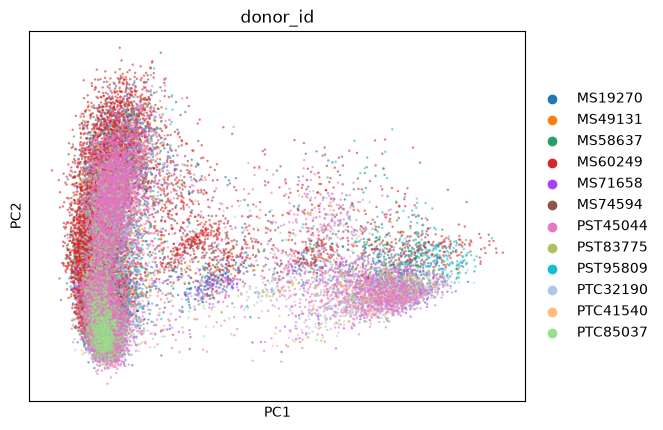


MEDIAN PCA POSITION BY DONOR


/tmp/ipykernel_261804/1892939897.py:138: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(


,PC1,PC2
donor_id,,
MS19270,-2.085,-0.665
MS49131,-1.949,-0.685
MS58637,-2.291,-0.702
MS60249,-2.241,0.961
MS71658,-2.259,-1.469
MS74594,-2.318,-1.484
PST45044,-1.823,-1.285
PST83775,-1.835,-1.179
PST95809,-0.359,0.929


In [16]:
# ============================================================
# STEP 15 — PCA + INITIAL DONOR-EFFECT DIAGNOSTIC
# ============================================================
#
# We now reduce the normalized expression data using PCA.
#
# PCA will use ONLY the 3,000 genes marked:
#
#       highly_variable == True
#
# However, we keep all 33,694 genes in the AnnData object.
#
# IMPORTANT:
#
# At this stage we are NOT performing batch correction.
#
# First we want to SEE the natural structure of the data:
#
#       • Do cells separate primarily by biological cell type?
#       • Is there strong donor/library structure?
#       • Is one donor behaving unusually?
#
# We should diagnose this BEFORE deciding whether any
# integration/batch-correction method is necessary.
#
# Disease status is also NOT used in the PCA calculation.
#
# ============================================================

import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Run PCA
# ------------------------------------------------------------

sc.tl.pca(
    adata_csf,
    n_comps=50,
    use_highly_variable=True,
    svd_solver="arpack",
    random_state=42
)


# ------------------------------------------------------------
# Variance explained
# ------------------------------------------------------------

variance_ratio = (
    adata_csf.uns["pca"]["variance_ratio"]
)


print(
    "========================================"
)

print(
    "PCA COMPLETE"
)

print(
    "========================================"
)


print("\nPCA coordinates:")
print(
    adata_csf.obsm["X_pca"].shape
)


print("\nVariance explained:")

for pc in range(10):

    print(
        f"PC{pc + 1}: "
        f"{variance_ratio[pc] * 100:.2f}%"
    )


print(
    "\nVariance explained by first 10 PCs:"
)

print(
    f"{variance_ratio[:10].sum() * 100:.2f}%"
)


# ============================================================
# PCA PLOT COLORED BY DONOR
# ============================================================

sc.pl.pca(
    adata_csf,
    color="donor_id",
    components=["1,2"],
    size=12,
    alpha=0.6,
    show=True
)


# ============================================================
# DONOR CENTROIDS IN PCA SPACE
# ============================================================
#
# Instead of relying only on the visual plot, calculate the
# median PC1 and PC2 position for each donor.
#
# This gives us a compact numerical view of whether particular
# donors occupy unusually different PCA regions.
# ============================================================

pca_df = pd.DataFrame(
    adata_csf.obsm["X_pca"][:, :2],
    columns=[
        "PC1",
        "PC2"
    ],
    index=adata_csf.obs_names
)


pca_df["donor_id"] = (
    adata_csf.obs["donor_id"].values
)


donor_pca_centroids = (
    pca_df
    .groupby(
        "donor_id"
    )[
        [
            "PC1",
            "PC2"
        ]
    ]
    .median()
    .round(3)
)


print(
    "\n========================================"
)

print(
    "MEDIAN PCA POSITION BY DONOR"
)

print(
    "========================================"
)

display(
    donor_pca_centroids
)

/tmp/ipykernel_261804/3535418374.py:81: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


LEIDEN CLUSTERING COMPLETE

Number of clusters:
12

Cells per cluster:
leiden
0     6131
1     5878
2     5077
3     4934
4     4464
5     2143
6     1985
7     1343
8      723
9      559
10     479
11     319
Name: count, dtype: int64


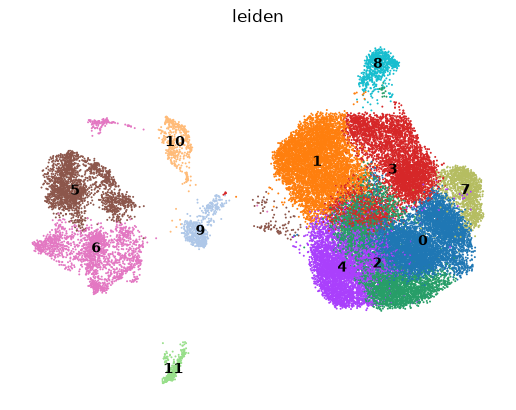

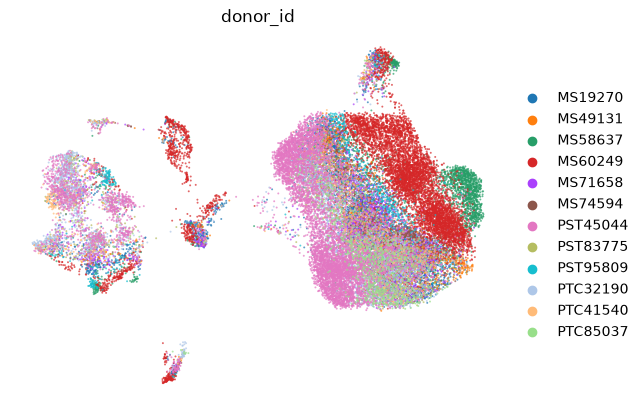


DONOR % WITHIN EACH LEIDEN CLUSTER


donor_id,MS19270,MS49131,MS58637,MS60249,MS71658,MS74594,PST45044,PST83775,PST95809,PTC32190,PTC41540,PTC85037
leiden,,,,,,,,,,,,
0,14.4,7.5,3.2,35.3,11.6,5.1,6.0,2.7,0.9,6.7,3.3,3.3
1,15.8,6.7,1.9,1.8,5.1,2.8,44.2,3.6,2.5,11.6,2.6,1.5
2,26.8,5.8,2.2,1.9,16.4,4.5,8.0,4.9,3.6,11.0,5.7,9.4
3,4.0,0.9,4.3,74.3,8.9,1.3,1.9,0.6,0.3,1.4,1.1,1.0
4,0.7,0.3,1.3,0.6,2.9,0.3,74.6,2.6,0.2,12.0,0.9,3.4
5,3.3,0.7,1.6,3.5,6.2,0.0,36.9,9.4,5.0,25.7,7.7,0.1
6,12.4,3.7,6.2,12.3,9.5,1.3,19.3,6.7,4.7,18.3,4.6,1.0
7,0.0,0.0,92.7,5.2,0.5,0.0,0.9,0.0,0.6,0.1,0.0,0.0
8,15.6,4.8,20.6,31.1,9.8,1.0,6.8,3.3,2.4,2.4,1.5,0.7


In [17]:
# ============================================================
# STEP 16 — NEIGHBOR GRAPH, UMAP AND LEIDEN CLUSTERING
# ============================================================
#
# PCA inspection showed:
#
#   • substantial overlap between donors
#   • major structure shared across multiple donors
#   • some donor-specific shifts, but no evidence that the
#     first PCs simply represent 12 separate donor batches
#
# Therefore we do NOT batch-correct at this stage.
#
# We now construct:
#
#       PCA
#        ↓
#   neighbor graph
#        ↓
#       UMAP
#        ↓
#   Leiden clusters
#
# These clusters are EXPLORATORY.
#
# They are NOT yet cell-type annotations.
#
# We will subsequently examine:
#
#       canonical immune markers
#       cluster marker genes
#       donor representation per cluster
#
# before assigning biological labels.
#
# ============================================================

import scanpy as sc
import pandas as pd


# ------------------------------------------------------------
# 1. Construct neighborhood graph
#
# We use:
#
#       15 nearest neighbors
#       first 30 PCs
#
# 30 PCs is a reasonable starting point for this heterogeneous
# immune-cell dataset.
# ------------------------------------------------------------

sc.pp.neighbors(
    adata_csf,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)


# ------------------------------------------------------------
# 2. Calculate UMAP
# ------------------------------------------------------------

sc.tl.umap(
    adata_csf,
    random_state=42
)


# ------------------------------------------------------------
# 3. Leiden clustering
#
# Start with moderate resolution = 0.5.
#
# We are NOT trying to maximize the number of clusters.
# We first want broad immune populations.
# ------------------------------------------------------------

sc.tl.leiden(
    adata_csf,
    resolution=0.5,
    key_added="leiden",
    random_state=42
)


# ------------------------------------------------------------
# 4. Basic cluster summary
# ------------------------------------------------------------

print(
    "========================================"
)

print(
    "LEIDEN CLUSTERING COMPLETE"
)

print(
    "========================================"
)


print("\nNumber of clusters:")

print(
    adata_csf.obs["leiden"].nunique()
)


print("\nCells per cluster:")

print(
    adata_csf.obs["leiden"]
    .value_counts()
    .sort_index(
        key=lambda x: x.astype(int)
    )
)


# ============================================================
# 5. UMAP COLORED BY LEIDEN CLUSTER
# ============================================================

sc.pl.umap(
    adata_csf,
    color="leiden",
    legend_loc="on data",
    frameon=False,
    size=8
)


# ============================================================
# 6. UMAP COLORED BY DONOR
# ============================================================
#
# This is important:
#
# If clusters are largely shared by multiple donors, that
# supports biological rather than donor-specific structure.
#
# ============================================================

sc.pl.umap(
    adata_csf,
    color="donor_id",
    frameon=False,
    size=8,
    alpha=0.7
)


# ============================================================
# 7. DONOR REPRESENTATION WITHIN EACH CLUSTER
# ============================================================
#
# Calculate the percentage contribution of each donor to each
# Leiden cluster.
#
# We don't expect equal percentages because donors have very
# different total cell numbers.
#
# But a cluster that is almost entirely one donor deserves
# additional scrutiny before biological interpretation.
#
# ============================================================

cluster_donor_counts = pd.crosstab(
    adata_csf.obs["leiden"],
    adata_csf.obs["donor_id"]
)


cluster_donor_pct = (
    cluster_donor_counts
    .div(
        cluster_donor_counts.sum(axis=1),
        axis=0
    )
    * 100
)


print(
    "\n========================================"
)

print(
    "DONOR % WITHIN EACH LEIDEN CLUSTER"
)

print(
    "========================================"
)


display(
    cluster_donor_pct.round(1)
)

CANONICAL MARKER CHECK

Missing markers:
None


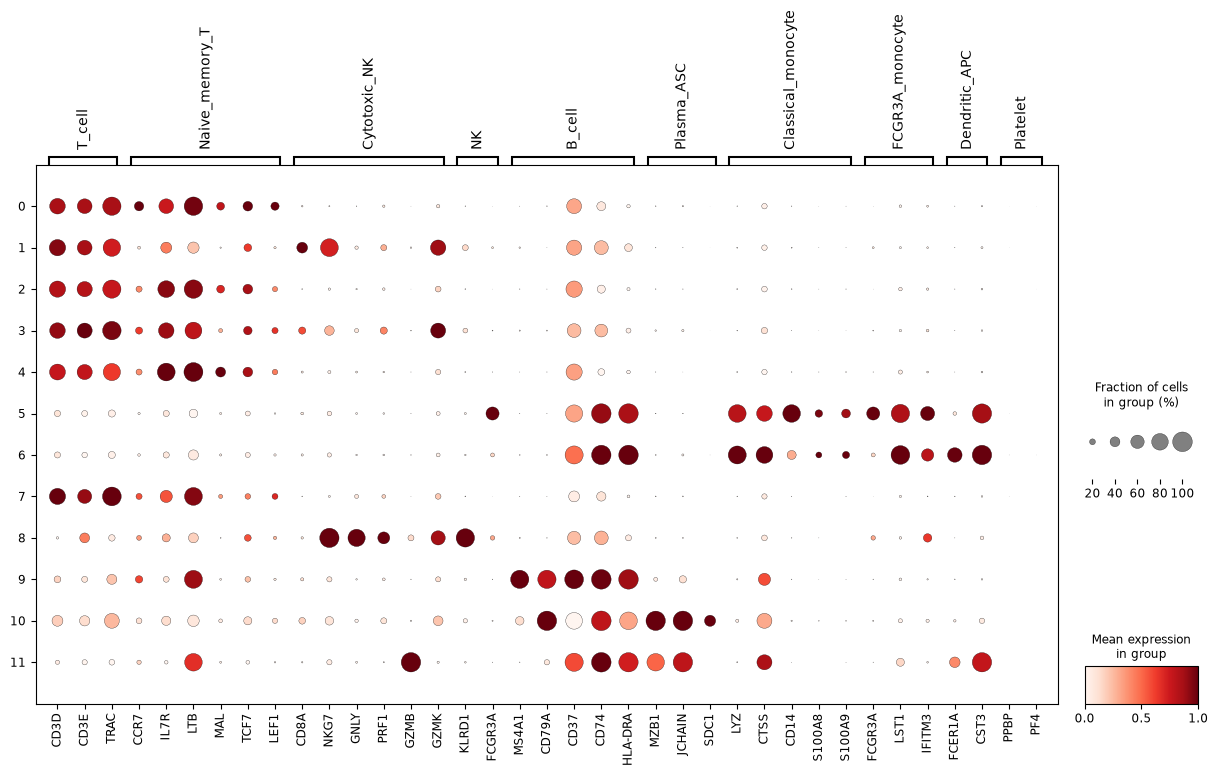

In [18]:
# ============================================================
# STEP 17 — CANONICAL IMMUNE-MARKER INSPECTION
# ============================================================
#
# We obtained 12 Leiden clusters.
#
# Some clusters are well represented across donors, whereas
# others are strongly enriched for individual donors.
#
# IMPORTANT:
#
# We therefore DO NOT assign biological labels from the UMAP
# shape or Leiden number alone.
#
# Instead, we inspect established marker genes representing
# the major immune-cell populations expected in CSF:
#
#   Pan-T cells:
#       CD3D, CD3E, TRAC
#
#   Naive / memory-like T cells:
#       CCR7, IL7R, LTB, MAL, TCF7, LEF1
#
#   Cytotoxic T / NK-like programs:
#       CD8A, NKG7, GNLY, PRF1, GZMB, GZMK
#
#   NK cells:
#       NKG7, GNLY, KLRD1, FCGR3A
#
#   B cells:
#       MS4A1, CD79A, CD37, CD74, HLA-DRA
#
#   Plasma / antibody-secreting cells:
#       MZB1, JCHAIN, SDC1
#
#   Classical monocytes:
#       LYZ, CTSS, CD14, S100A8, S100A9
#
#   FCGR3A+ monocytes:
#       LYZ, FCGR3A, LST1, IFITM3
#
#   Dendritic / APC-like:
#       FCER1A, CST3, CD74, HLA-DRA
#
#   Platelets:
#       PPBP, PF4
#
# We are NOT yet calling any cluster a particular cell type.
#
# ============================================================


marker_panel = {

    "T_cell": [
        "CD3D",
        "CD3E",
        "TRAC"
    ],

    "Naive_memory_T": [
        "CCR7",
        "IL7R",
        "LTB",
        "MAL",
        "TCF7",
        "LEF1"
    ],

    "Cytotoxic_NK": [
        "CD8A",
        "NKG7",
        "GNLY",
        "PRF1",
        "GZMB",
        "GZMK"
    ],

    "NK": [
        "KLRD1",
        "FCGR3A"
    ],

    "B_cell": [
        "MS4A1",
        "CD79A",
        "CD37",
        "CD74",
        "HLA-DRA"
    ],

    "Plasma_ASC": [
        "MZB1",
        "JCHAIN",
        "SDC1"
    ],

    "Classical_monocyte": [
        "LYZ",
        "CTSS",
        "CD14",
        "S100A8",
        "S100A9"
    ],

    "FCGR3A_monocyte": [
        "FCGR3A",
        "LST1",
        "IFITM3"
    ],

    "Dendritic_APC": [
        "FCER1A",
        "CST3"
    ],

    "Platelet": [
        "PPBP",
        "PF4"
    ]
}


# ------------------------------------------------------------
# Check that markers exist in this dataset
# ------------------------------------------------------------

marker_panel_present = {}

missing_markers = []


for group, genes in marker_panel.items():

    present = [
        gene
        for gene in genes
        if gene in adata_csf.var_names
    ]

    missing = [
        gene
        for gene in genes
        if gene not in adata_csf.var_names
    ]

    marker_panel_present[group] = present
    missing_markers.extend(missing)


print(
    "========================================"
)

print(
    "CANONICAL MARKER CHECK"
)

print(
    "========================================"
)


print("\nMissing markers:")
print(
    missing_markers
    if missing_markers
    else "None"
)


# ------------------------------------------------------------
# Canonical marker dot plot
#
# Dot size:
#     fraction of cells expressing the gene
#
# Color:
#     average expression
#
# ------------------------------------------------------------

sc.pl.dotplot(
    adata_csf,
    marker_panel_present,
    groupby="leiden",
    standard_scale="var",
    dendrogram=False,
    figsize=(15, 7)
)

TOP 15 DATA-DRIVEN MARKERS PER CLUSTER


,top_15_markers
group,
0,"LDHB, LTB, RPS6, RPL11, TRAC, RPL13, SELL, CCR..."
1,"CCL5, NKG7, CST7, CCL4, CMC1, GZMA, HCST, GZMK..."
2,"KLRB1, RPS28, RPL41, RPS21, RPLP2, RPL38, RPL3..."
3,"HLA-C, CCL5, HLA-B, BTG1, B2M, ZFP36L2, GZMK, ..."
4,"RPS12, CD69, RPL30, TPT1, RPLP2, RPL9, RPL32, ..."
5,"FTL, FTH1, C1QB, C1QA, C1QC, TYROBP, AIF1, CST..."
6,"HLA-DPB1, HLA-DRA, HLA-DPA1, CST3, CD74, HLA-D..."
7,"CD69, RPL34, IER2, ACTB, RPL41, RPS29, RPL21, ..."
8,"KLRD1, NKG7, TRDC, CTSW, GNLY, TYROBP, CMC1, F..."


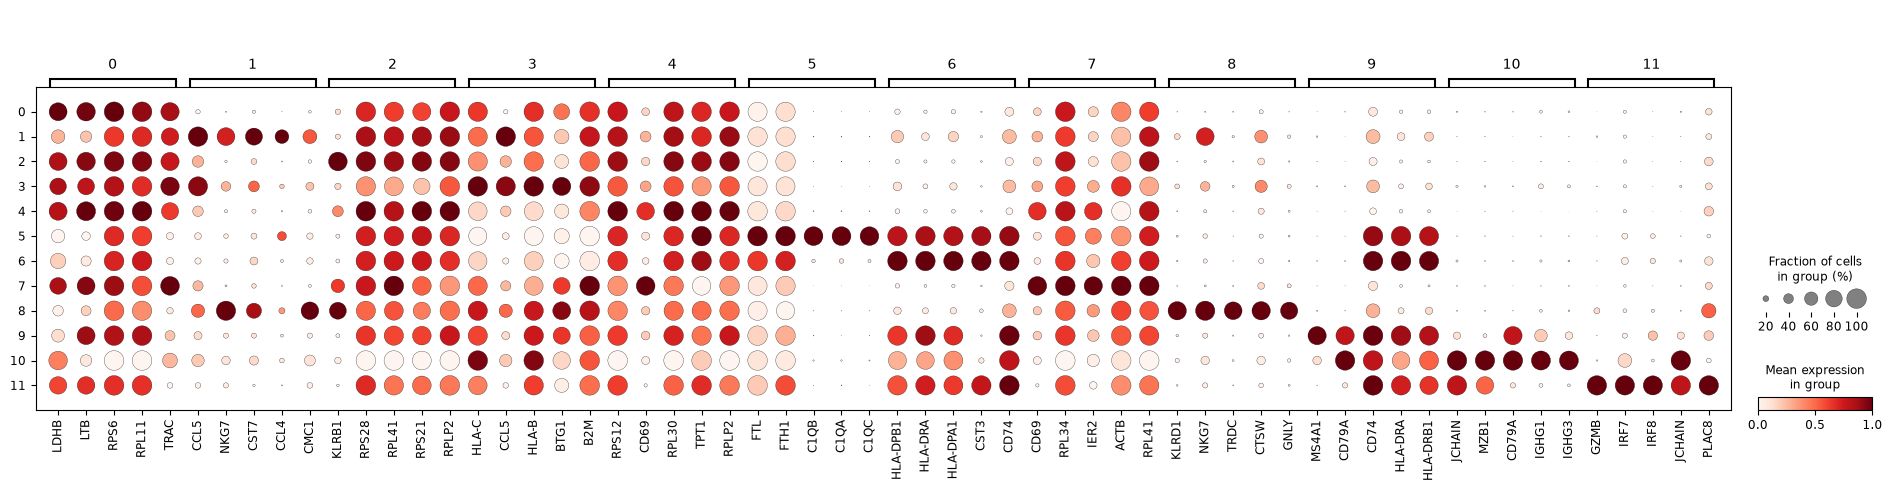

In [19]:
# ============================================================
# STEP 18 — DATA-DRIVEN MARKER GENES FOR LEIDEN CLUSTERS
# ============================================================
#
# Canonical marker inspection suggested broad identities:
#
#   clusters 0/2/4/7  -> naive/memory-like T-cell region
#   clusters 1/3      -> more cytotoxic/effector-like T cells
#   cluster 8         -> NK-like
#   cluster 9         -> B-cell-like
#   clusters 5/6      -> myeloid/APC-like
#   cluster 10        -> plasma/ASC-like
#
# However, these are still provisional interpretations.
#
# We now identify genes enriched in each Leiden cluster
# compared with all other cells.
#
# WHY?
#
# 1. Confirm the canonical-marker interpretation.
#
# 2. Investigate donor-dominated clusters:
#
#       cluster 3 -> strongly MS60249 enriched
#       cluster 4 -> strongly PST45044 enriched
#       cluster 7 -> strongly MS58637 enriched
#       cluster 10 -> strongly MS60249 enriched
#
# A donor-dominated cluster is not automatically an artifact.
# It could represent a genuine cell population that happens
# to be abundant in one donor.
#
# Therefore we inspect its biological markers before deciding.
#
# IMPORTANT:
#
# This marker analysis is for CELL-TYPE ANNOTATION.
#
# It is NOT our MS-versus-IIH differential-expression test.
# Cells are being used descriptively here to characterize
# clusters.
#
# The eventual disease comparison will use donor-level
# pseudobulk counts.
#
# ============================================================


# ------------------------------------------------------------
# Calculate cluster marker genes
# ------------------------------------------------------------

sc.tl.rank_genes_groups(
    adata_csf,
    groupby="leiden",
    method="wilcoxon",
    key_added="leiden_markers"
)


# ------------------------------------------------------------
# Display top 15 marker genes for each cluster
# ------------------------------------------------------------

marker_df = sc.get.rank_genes_groups_df(
    adata_csf,
    group=None,
    key="leiden_markers"
)


top_markers = (
    marker_df
    .sort_values(
        ["group", "scores"],
        ascending=[True, False]
    )
    .groupby(
        "group",
        observed=True
    )
    .head(15)
)


# ------------------------------------------------------------
# Compact table:
#
# one row per cluster
# top 15 genes shown together
# ------------------------------------------------------------

top_marker_table = (
    top_markers
    .groupby(
        "group",
        observed=True
    )["names"]
    .apply(
        lambda genes:
        ", ".join(genes.astype(str))
    )
    .to_frame(
        name="top_15_markers"
    )
)


print(
    "========================================"
)

print(
    "TOP 15 DATA-DRIVEN MARKERS PER CLUSTER"
)

print(
    "========================================"
)


display(
    top_marker_table
)


# ------------------------------------------------------------
# Marker visualization
# ------------------------------------------------------------

sc.pl.rank_genes_groups_dotplot(
    adata_csf,
    key="leiden_markers",
    n_genes=5,
    groupby="leiden",
    standard_scale="var",
    dendrogram=False
)

REFINED MARKERS PRESENT IN DATASET
T_lineage: ['CD3D', 'CD3E', 'TRAC', 'CD247']
Naive_memory: ['CCR7', 'SELL', 'IL7R', 'TCF7', 'LEF1', 'MAL', 'LTB']
Cytotoxic: ['CCL5', 'NKG7', 'GZMK', 'GZMB', 'PRF1', 'CTSW']
NK: ['GNLY', 'KLRD1', 'KLRF1', 'FCGR3A', 'TYROBP']
Gamma_delta_T: ['TRDC', 'TRGC1', 'TRGC2']
B_Plasma: ['MS4A1', 'CD79A', 'CD79B', 'MZB1', 'JCHAIN']
Myeloid: ['LYZ', 'LST1', 'TYROBP', 'AIF1', 'CST3']
APC_DC: ['FCER1A', 'CD1C', 'CLEC10A', 'CD74']
pDC_candidate: ['GZMB', 'TCF4', 'IL3RA', 'CLEC4C', 'IRF7', 'IRF8', 'SERPINF1']


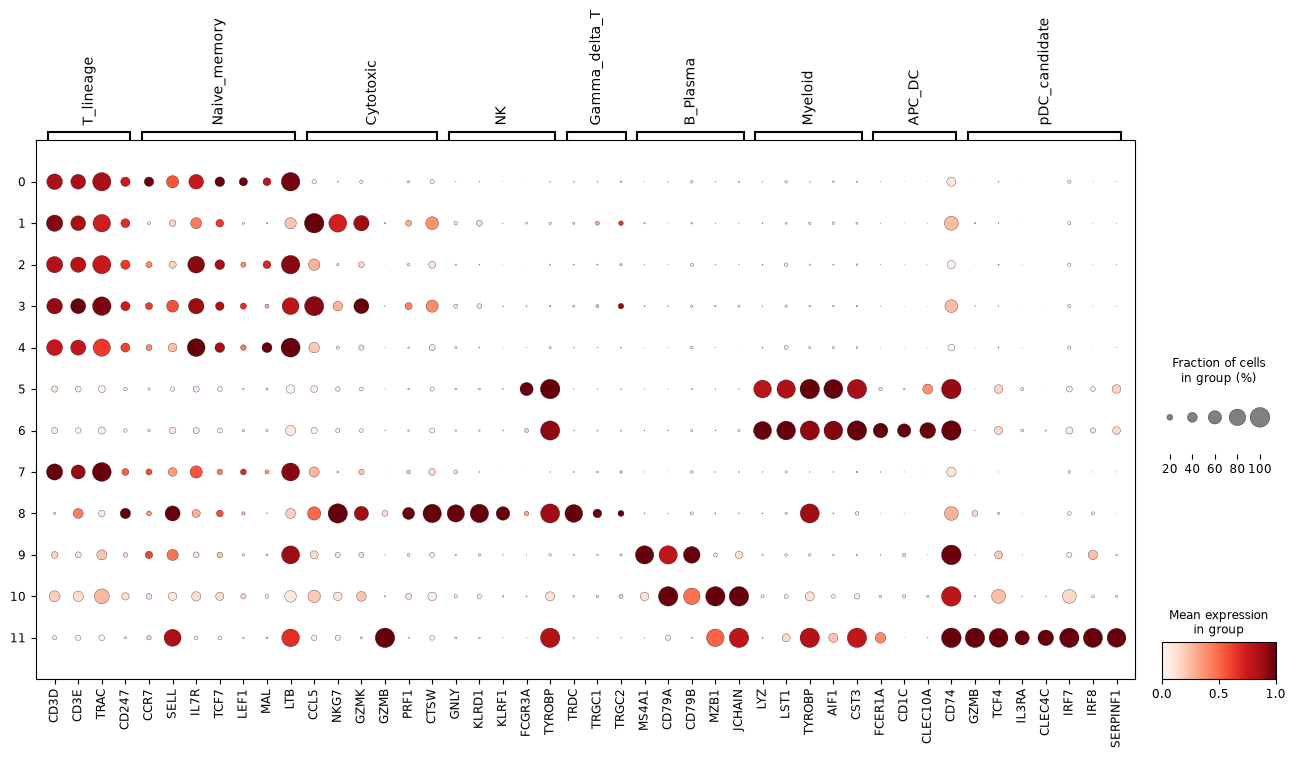

In [20]:
# ============================================================
# STEP 19 — REFINE T-CELL AND AMBIGUOUS CLUSTER IDENTITIES
# ============================================================
#
# Our first marker analysis strongly supports several broad
# populations, but we want to be especially careful with:
#
#       clusters 0, 2, 4, 7  -> candidate broad T cells
#       cluster 8            -> NK / cytotoxic lymphocytes
#       cluster 11           -> ambiguous GZMB/IRF7/IRF8 cluster
#
# This matters because our validation analysis will eventually
# extract a T-cell population comparable to the discovery
# broad naive/memory-like T-cell population.
#
# We therefore inspect a more focused panel.
#
# ============================================================


refined_markers = {

    # General T-cell identity
    "T_lineage": [
        "CD3D", "CD3E", "TRAC", "CD247"
    ],

    # Naive / central-memory-like program
    "Naive_memory": [
        "CCR7", "SELL", "IL7R",
        "TCF7", "LEF1", "MAL", "LTB"
    ],

    # Cytotoxic T-cell program
    "Cytotoxic": [
        "CCL5", "NKG7", "GZMK",
        "GZMB", "PRF1", "CTSW"
    ],

    # NK identity
    "NK": [
        "GNLY", "KLRD1", "KLRF1",
        "FCGR3A", "TYROBP"
    ],

    # Gamma-delta T-cell indicators
    "Gamma_delta_T": [
        "TRDC", "TRGC1", "TRGC2"
    ],

    # B / plasma
    "B_Plasma": [
        "MS4A1", "CD79A", "CD79B",
        "MZB1", "JCHAIN"
    ],

    # Myeloid
    "Myeloid": [
        "LYZ", "LST1", "TYROBP",
        "AIF1", "CST3"
    ],

    # Conventional dendritic/APC
    "APC_DC": [
        "FCER1A", "CD1C",
        "CLEC10A", "CD74"
    ],

    # pDC-associated markers
    #
    # Cluster 11 expresses GZMB + IRF7 + IRF8.
    # This combination motivates checking pDC-associated
    # markers, but we will NOT label the cluster as pDC
    # unless the marker pattern supports it.
    "pDC_candidate": [
        "GZMB", "GZMB",
        "GZMB", "TCF4",
        "IL3RA", "GZMB",
        "CLEC4C", "IRF7",
        "IRF8", "SERPINF1"
    ]
}


# ------------------------------------------------------------
# Remove duplicate genes and genes absent from the dataset
# ------------------------------------------------------------

refined_present = {}

for group, genes in refined_markers.items():

    genes_unique = list(dict.fromkeys(genes))

    refined_present[group] = [
        gene
        for gene in genes_unique
        if gene in adata_csf.var_names
    ]


print(
    "========================================"
)

print(
    "REFINED MARKERS PRESENT IN DATASET"
)

print(
    "========================================"
)

for group, genes in refined_present.items():

    print(
        f"{group}: {genes}"
    )


# ------------------------------------------------------------
# Refined dot plot
# ------------------------------------------------------------

sc.pl.dotplot(
    adata_csf,
    refined_present,
    groupby="leiden",
    standard_scale="var",
    dendrogram=False,
    figsize=(16, 7)
)

BROAD CELL-TYPE ANNOTATION

Unannotated cells:
0

Cells per broad cell type:
cell_type
Naive/memory-like T                         17015
Cytotoxic T                                  5878
Cytotoxic/activated T                        4934
Monocyte/macrophage-like                     2143
Dendritic/APC-like                           1985
NK/gamma-delta-like cytotoxic lymphocyte      723
B cell                                        559
Plasma/ASC                                    479
pDC-like                                      319
Name: count, dtype: int64


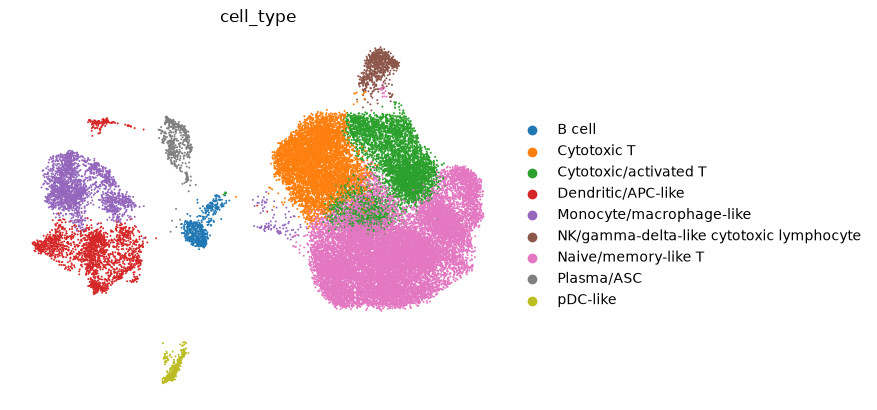


CANDIDATE VALIDATION T-CELL POPULATION

Cells:
17015

Genes:
33694

Number of donors:
12

Candidate naive/memory-like T cells per donor:


,n_T_cells
donor_id,
MS19270,2276
MS49131,766
MS58637,1615
MS60249,2361
MS71658,1677
MS74594,553
PST45044,4111
PST83775,531
PST95809,255


In [21]:
# ============================================================
# STEP 20 — CREATE CONSERVATIVE BROAD CELL-TYPE ANNOTATION
# ============================================================
#
# Annotation is based on:
#
#   1. canonical immune-cell marker expression
#   2. data-driven Leiden marker genes
#   3. refined lineage/state marker inspection
#
# We intentionally use BROAD labels.
#
# In particular, clusters 0, 2, 4 and 7 are grouped as:
#
#       Naive/memory-like T
#
# rather than forcing fine T-cell subtype labels.
#
# This gives us a population conceptually comparable to the
# broad naive/memory-like T-cell population used in the
# discovery GSE133028 analysis.
#
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Leiden -> broad cell-type mapping
# ------------------------------------------------------------

cell_type_map = {

    "0": "Naive/memory-like T",

    "1": "Cytotoxic T",

    "2": "Naive/memory-like T",

    "3": "Cytotoxic/activated T",

    "4": "Naive/memory-like T",

    "5": "Monocyte/macrophage-like",

    "6": "Dendritic/APC-like",

    "7": "Naive/memory-like T",

    "8": "NK/gamma-delta-like cytotoxic lymphocyte",

    "9": "B cell",

    "10": "Plasma/ASC",

    "11": "pDC-like"
}


adata_csf.obs["cell_type"] = (
    adata_csf.obs["leiden"]
    .astype(str)
    .map(cell_type_map)
)


# ------------------------------------------------------------
# 2. Verify every cell received an annotation
# ------------------------------------------------------------

print(
    "========================================"
)

print(
    "BROAD CELL-TYPE ANNOTATION"
)

print(
    "========================================"
)


print("\nUnannotated cells:")

print(
    adata_csf.obs["cell_type"]
    .isna()
    .sum()
)


print("\nCells per broad cell type:")

print(
    adata_csf.obs["cell_type"]
    .value_counts()
)


# ------------------------------------------------------------
# 3. UMAP with broad annotation
# ------------------------------------------------------------

sc.pl.umap(
    adata_csf,
    color="cell_type",
    frameon=False,
    size=8,
    legend_loc="right margin"
)


# ============================================================
# 4. FOCUS ON THE VALIDATION POPULATION
# ============================================================
#
# Extract the broad naive/memory-like T-cell population.
#
# IMPORTANT:
#
# This is NOT yet the pseudobulk matrix.
#
# First we must verify that all donors contribute enough cells
# to this population.
#
# ============================================================

validation_t = adata_csf[
    adata_csf.obs["cell_type"]
    == "Naive/memory-like T"
].copy()


print(
    "\n========================================"
)

print(
    "CANDIDATE VALIDATION T-CELL POPULATION"
)

print(
    "========================================"
)


print("\nCells:")
print(
    validation_t.n_obs
)


print("\nGenes:")
print(
    validation_t.n_vars
)


print("\nNumber of donors:")
print(
    validation_t.obs["donor_id"]
    .nunique()
)


# ------------------------------------------------------------
# 5. Number of candidate T cells contributed by each donor
# ------------------------------------------------------------

t_cells_per_donor = (
    validation_t.obs["donor_id"]
    .value_counts()
    .sort_index()
)


print(
    "\nCandidate naive/memory-like T cells per donor:"
)

display(
    t_cells_per_donor.to_frame(
        name="n_T_cells"
    )
)

In [23]:
# ============================================================
# STEP 22 — ADD DONOR-LEVEL CLINICAL METADATA
# ============================================================
#
# We now attach donor-level metadata to the candidate
# validation T-cell population.
#
# IMPORTANT:
#
# Controls in GSE138266 are IIH controls:
#
#       IIH = idiopathic intracranial hypertension
#
# Therefore this validation comparison is:
#
#       MS versus IIH
#
# NOT:
#
#       MS versus healthy controls
#
# The CSF cohort contains:
#
#       6 MS donors
#       6 IIH donors
#
# Sex is also recorded because we need to verify that disease
# status is not confounded with sex, as happened in the
# rejected GSE286068 validation dataset.
#
# ============================================================

import pandas as pd


donor_metadata = pd.DataFrame({

    "donor_id": [
        "MS19270",
        "MS58637",
        "MS71658",
        "MS49131",
        "MS60249",
        "MS74594",
        "PST83775",
        "PTC32190",
        "PST95809",
        "PTC41540",
        "PST45044",
        "PTC85037"
    ],

    "disease_status": [
        "MS",
        "MS",
        "MS",
        "MS",
        "MS",
        "MS",
        "IIH",
        "IIH",
        "IIH",
        "IIH",
        "IIH",
        "IIH"
    ],

    "sex": [
        "F",
        "M",
        "F",
        "F",
        "F",
        "M",
        "M",
        "M",
        "F",
        "F",
        "F",
        "F"
    ]
}).set_index("donor_id")


# ------------------------------------------------------------
# Add the number of candidate T cells
# ------------------------------------------------------------

donor_metadata["n_T_cells"] = (
    validation_t.obs["donor_id"]
    .value_counts()
    .reindex(donor_metadata.index)
)


print(
    "========================================"
)

print(
    "VALIDATION DONOR METADATA"
)

print(
    "========================================"
)

display(donor_metadata)


# ------------------------------------------------------------
# Verify disease-group size
# ------------------------------------------------------------

print("\nDonors by disease status:")

print(
    donor_metadata["disease_status"]
    .value_counts()
)


# ------------------------------------------------------------
# CRITICAL CONFOUNDING CHECK
#
# Compare disease status × sex.
# ------------------------------------------------------------

print("\n========================================")
print("DISEASE STATUS × SEX")
print("========================================")

disease_sex_table = pd.crosstab(
    donor_metadata["disease_status"],
    donor_metadata["sex"]
)

display(disease_sex_table)


# ------------------------------------------------------------
# Verify all validation_t donors have metadata
# ------------------------------------------------------------

missing_metadata = (
    set(validation_t.obs["donor_id"].unique())
    - set(donor_metadata.index)
)


print("\nDonors missing metadata:")
print(
    missing_metadata
    if missing_metadata
    else "None"
)

VALIDATION DONOR METADATA


,disease_status,sex,n_T_cells
donor_id,,,
MS19270,MS,F,2276
MS58637,MS,M,1615
MS71658,MS,F,1677
MS49131,MS,F,766
MS60249,MS,F,2361
MS74594,MS,M,553
PST83775,IIH,M,531
PTC32190,IIH,M,1510
PST95809,IIH,F,255



Donors by disease status:
disease_status
MS     6
IIH    6
Name: count, dtype: int64

DISEASE STATUS × SEX


sex,F,M
disease_status,,
IIH,4,2
MS,4,2



Donors missing metadata:
None


In [24]:
# ============================================================
# STEP 23 — BUILD DONOR-LEVEL RAW-COUNT PSEUDOBULK
# ============================================================
#
# We have:
#
#       17,015 broad naive/memory-like T cells
#       12 biological donors
#       6 MS
#       6 IIH
#
# We now aggregate RAW UMI counts across all candidate
# T cells belonging to the same donor.
#
# Conceptually:
#
#       hundreds/thousands of cells
#                ↓
#          SUM raw counts
#                ↓
#        ONE expression profile
#          per biological donor
#
# Therefore our DE dataset will have:
#
#       12 rows = donors
#       33,694 columns = genes
#
# IMPORTANT:
#
# We MUST use:
#
#       validation_t.layers["counts"]
#
# and NOT validation_t.X.
#
# X contains normalized/log-transformed values and is
# unsuitable for DESeq2 pseudobulk analysis.
#
# ============================================================

import numpy as np
import pandas as pd
from scipy import sparse


# ------------------------------------------------------------
# 1. Verify raw counts before aggregation
# ------------------------------------------------------------

raw_counts = validation_t.layers["counts"]

print(
    "========================================"
)

print(
    "RAW COUNT CHECK"
)

print(
    "========================================"
)

print("\nRaw-count layer present:")
print(
    "counts" in validation_t.layers
)


if sparse.issparse(raw_counts):

    raw_values = raw_counts.data

else:

    raw_values = np.asarray(raw_counts).ravel()


print("\nRaw counts integer-like:")

print(
    np.allclose(
        raw_values,
        np.round(raw_values)
    )
)


# ------------------------------------------------------------
# 2. Aggregate raw counts donor by donor
# ------------------------------------------------------------

pseudobulk_rows = []


for donor in donor_metadata.index:

    donor_mask = (
        validation_t.obs["donor_id"]
        .astype(str)
        .values
        == donor
    )

    donor_counts = (
        validation_t.layers["counts"][
            donor_mask,
            :
        ]
    )


    # Sum all cells from this donor for every gene
    donor_sum = np.asarray(
        donor_counts.sum(axis=0)
    ).ravel()


    pseudobulk_rows.append(
        donor_sum
    )


# ------------------------------------------------------------
# 3. Construct donor × gene matrix
# ------------------------------------------------------------

pseudobulk_counts = pd.DataFrame(
    np.vstack(pseudobulk_rows),
    index=donor_metadata.index,
    columns=validation_t.var_names
)


# Convert explicitly to integers
pseudobulk_counts = (
    pseudobulk_counts
    .round()
    .astype(np.int64)
)


# ------------------------------------------------------------
# 4. Create pseudobulk metadata
# ------------------------------------------------------------

pseudobulk_meta = (
    donor_metadata.copy()
)


# Raw library size = total T-cell UMIs per donor
pseudobulk_meta["library_size"] = (
    pseudobulk_counts.sum(axis=1)
)


# Number of genes with at least one raw count
pseudobulk_meta["detected_genes"] = (
    (pseudobulk_counts > 0)
    .sum(axis=1)
)


# ------------------------------------------------------------
# 5. Verify pseudobulk structure
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "PSEUDOBULK COMPLETE"
)

print(
    "========================================"
)


print("\nPseudobulk matrix shape:")
print(
    pseudobulk_counts.shape
)


print("\nNumber of biological replicates:")
print(
    pseudobulk_counts.shape[0]
)


print("\nAll pseudobulk counts integer-like:")

print(
    np.allclose(
        pseudobulk_counts.values,
        np.round(
            pseudobulk_counts.values
        )
    )
)


print("\nTotal pseudobulk UMIs:")

print(
    f"{pseudobulk_counts.values.sum():,.0f}"
)


# ------------------------------------------------------------
# 6. Display donor-level QC
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "PSEUDOBULK QC BY DONOR"
)

print(
    "========================================"
)


display(
    pseudobulk_meta[
        [
            "disease_status",
            "sex",
            "n_T_cells",
            "library_size",
            "detected_genes"
        ]
    ]
)


# ------------------------------------------------------------
# 7. Verify that pseudobulk contains exactly the raw UMIs
#    present in the selected validation T cells
# ------------------------------------------------------------

selected_cell_umis = (
    validation_t.layers["counts"].sum()
)


pseudobulk_umis = (
    pseudobulk_counts.values.sum()
)


print(
    "\nUMI conservation check:"
)

print(
    f"Selected-cell raw UMIs: {selected_cell_umis:,.0f}"
)

print(
    f"Pseudobulk raw UMIs:    {pseudobulk_umis:,.0f}"
)

print(
    "Exact match:",
    np.isclose(
        selected_cell_umis,
        pseudobulk_umis
    )
)

RAW COUNT CHECK

Raw-count layer present:
True

Raw counts integer-like:
True

PSEUDOBULK COMPLETE

Pseudobulk matrix shape:
(12, 33694)

Number of biological replicates:
12

All pseudobulk counts integer-like:
True

Total pseudobulk UMIs:
52,571,675

PSEUDOBULK QC BY DONOR


,disease_status,sex,n_T_cells,library_size,detected_genes
donor_id,,,,,
MS19270,MS,F,2276,7761275,17383
MS58637,MS,M,1615,3056245,15814
MS71658,MS,F,1677,5267339,16760
MS49131,MS,F,766,2485546,15613
MS60249,MS,F,2361,4363063,16742
MS74594,MS,M,553,2732672,16204
PST83775,IIH,M,531,2060106,15477
PTC32190,IIH,M,1510,5260364,16775
PST95809,IIH,F,255,603101,12371



UMI conservation check:
Selected-cell raw UMIs: 52,571,675
Pseudobulk raw UMIs:    52,571,675
Exact match: True


LOW-EXPRESSION FILTER

Genes before filtering:
33694

Genes retained:
11358

Genes removed:
22336

Genes used for PCA:
3000

PSEUDOBULK PCA
PC1: 37.54%
PC2: 20.63%
PC3: 13.81%
PC4: 6.82%
PC5: 4.41%
PC6: 4.04%
PC7: 3.44%
PC8: 2.97%
PC9: 2.70%
PC10: 1.92%

Donor PCA coordinates:


,PC1,PC2,disease_status,sex,n_T_cells,library_size
donor_id,,,,,,
MS19270,-7.771,-13.811,MS,F,2276,7761275
MS58637,-28.397,31.723,MS,M,1615,3056245
MS71658,-14.360,-0.011,MS,F,1677,5267339
MS49131,-13.139,-1.420,MS,F,766,2485546
MS60249,-41.056,25.752,MS,F,2361,4363063
MS74594,-5.128,10.416,MS,M,553,2732672
PST83775,2.023,-9.407,IIH,M,531,2060106
PTC32190,-2.168,-13.605,IIH,M,1510,5260364
PST95809,78.676,36.604,IIH,F,255,603101


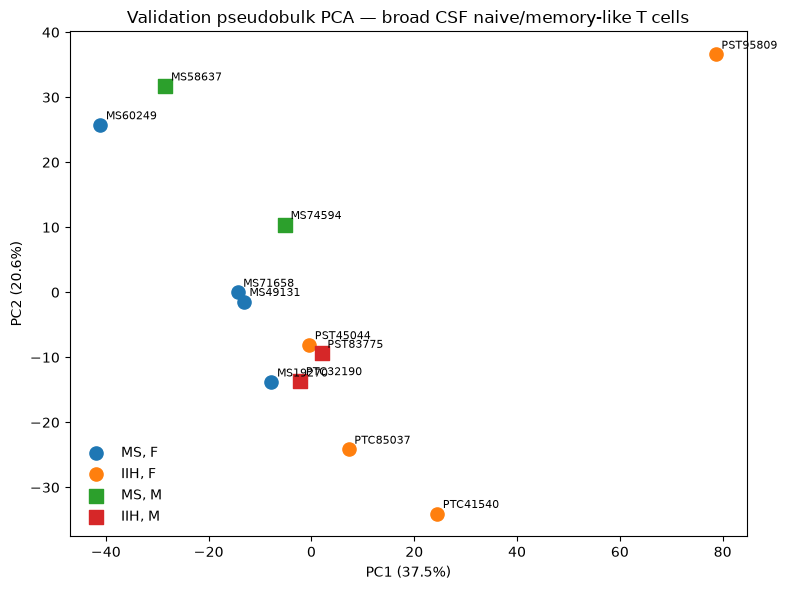


Filtered raw counts integer-like:
True


In [25]:
# ============================================================
# STEP 24 — LOW-EXPRESSION FILTERING + PSEUDOBULK PCA
# ============================================================
#
# We now move from cell-level exploration to donor-level QC.
#
# Biological replicate:
#
#       donor
#
# Therefore this PCA contains only:
#
#       12 points
#
# rather than 17,015 individual cells.
#
#
# ------------------------------------------------------------
# LOW-EXPRESSION FILTER
# ------------------------------------------------------------
#
# To remain consistent with the discovery analysis, retain
# genes having:
#
#       >= 10 raw counts
#
# in at least:
#
#       3 donors
#
# This removes extremely sparse genes before DESeq2 while
# retaining genes with reasonable donor-level evidence.
#
#
# ------------------------------------------------------------
# PCA TRANSFORMATION
# ------------------------------------------------------------
#
# PCA is exploratory QC only.
#
# For visualization we use:
#
#       raw counts
#           ↓
#          CPM
#           ↓
#       log2(CPM + 1)
#
# We then select the 3,000 genes with highest variance across
# donors for PCA.
#
# IMPORTANT:
#
# This transformation is NOT used for DESeq2.
#
# DESeq2 will receive the filtered RAW INTEGER counts.
#
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA


# ============================================================
# 1. LOW-EXPRESSION FILTER
# ============================================================

keep_genes = (
    (pseudobulk_counts >= 10)
    .sum(axis=0)
    >= 3
)


pseudobulk_counts_filtered = (
    pseudobulk_counts.loc[
        :,
        keep_genes
    ]
    .copy()
)


print(
    "========================================"
)

print(
    "LOW-EXPRESSION FILTER"
)

print(
    "========================================"
)


print("\nGenes before filtering:")
print(
    pseudobulk_counts.shape[1]
)


print("\nGenes retained:")
print(
    pseudobulk_counts_filtered.shape[1]
)


print("\nGenes removed:")
print(
    pseudobulk_counts.shape[1]
    - pseudobulk_counts_filtered.shape[1]
)


# ============================================================
# 2. CALCULATE CPM
# ============================================================

library_sizes = (
    pseudobulk_counts_filtered
    .sum(axis=1)
)


cpm = (
    pseudobulk_counts_filtered
    .div(
        library_sizes,
        axis=0
    )
    * 1_000_000
)


# ============================================================
# 3. LOG TRANSFORM FOR PCA ONLY
# ============================================================

log_cpm = np.log2(
    cpm + 1
)


# ============================================================
# 4. SELECT 3,000 MOST VARIABLE GENES
# ============================================================

gene_variance = (
    log_cpm.var(axis=0)
)


n_pca_genes = min(
    3000,
    log_cpm.shape[1]
)


top_variable_genes = (
    gene_variance
    .sort_values(
        ascending=False
    )
    .head(
        n_pca_genes
    )
    .index
)


pca_input = (
    log_cpm[
        top_variable_genes
    ]
)


print("\nGenes used for PCA:")
print(
    pca_input.shape[1]
)


# ============================================================
# 5. RUN PCA
# ============================================================

pca = PCA(
    n_components=min(
        10,
        pca_input.shape[0]
    )
)


pca_coordinates = (
    pca.fit_transform(
        pca_input
    )
)


pca_df = pd.DataFrame(
    pca_coordinates,
    index=pca_input.index,
    columns=[
        f"PC{i+1}"
        for i in range(
            pca_coordinates.shape[1]
        )
    ]
)


# Attach metadata
pca_df = (
    pca_df
    .join(
        pseudobulk_meta[
            [
                "disease_status",
                "sex",
                "n_T_cells",
                "library_size"
            ]
        ]
    )
)


# ============================================================
# 6. VARIANCE EXPLAINED
# ============================================================

print(
    "\n========================================"
)

print(
    "PSEUDOBULK PCA"
)

print(
    "========================================"
)


for i, ratio in enumerate(
    pca.explained_variance_ratio_
):

    print(
        f"PC{i+1}: "
        f"{ratio * 100:.2f}%"
    )


# ============================================================
# 7. DISPLAY PCA COORDINATES
# ============================================================

print(
    "\nDonor PCA coordinates:"
)

display(
    pca_df[
        [
            "PC1",
            "PC2",
            "disease_status",
            "sex",
            "n_T_cells",
            "library_size"
        ]
    ].round(3)
)


# ============================================================
# 8. PCA PLOT
# ============================================================
#
# Color represents disease status.
#
# Marker shape represents sex.
#
# Every point is ONE DONOR.
#
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


markers = {
    "F": "o",
    "M": "s"
}


for sex in ["F", "M"]:

    for disease in ["MS", "IIH"]:

        subset = pca_df[
            (pca_df["sex"] == sex)
            &
            (pca_df["disease_status"] == disease)
        ]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            marker=markers[sex],
            s=90,
            label=f"{disease}, {sex}"
        )


# Add donor names
for donor, row in pca_df.iterrows():

    ax.annotate(
        donor,
        (
            row["PC1"],
            row["PC2"]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )


ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

ax.set_title(
    "Validation pseudobulk PCA — broad CSF naive/memory-like T cells"
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. FINAL RAW-COUNT SAFETY CHECK
# ============================================================

print("\nFiltered raw counts integer-like:")

print(
    np.allclose(
        pseudobulk_counts_filtered.values,
        np.round(
            pseudobulk_counts_filtered.values
        )
    )
)

In [26]:
# ============================================================
# STEP 25 — CHECK WHETHER PSEUDOBULK PCA TRACKS TECHNICAL DEPTH
# ============================================================
#
# PST95809 is clearly separated on PC1.
#
# It is ALSO our smallest pseudobulk:
#
#       255 T cells
#       603,101 raw UMIs
#
# However:
#
#       being an outlier is NOT a reason to exclude a donor.
#
# Before differential expression, we ask whether PC1/PC2
# strongly track:
#
#       • pseudobulk library size
#       • number of T cells
#       • number of detected genes
#
# If PCA strongly follows sequencing depth, that would suggest
# a technical contribution to the donor structure.
#
# This is a QC diagnostic only.
#
# ============================================================

from scipy.stats import spearmanr
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Add detected-gene information to PCA table
# ------------------------------------------------------------

pca_qc = pca_df.copy()

pca_qc["detected_genes"] = (
    pseudobulk_meta.loc[
        pca_qc.index,
        "detected_genes"
    ]
)


# log10 library size is easier to compare because library
# sizes span a substantial range.
pca_qc["log10_library_size"] = np.log10(
    pca_qc["library_size"]
)


# Same idea for cell number.
pca_qc["log10_n_T_cells"] = np.log10(
    pca_qc["n_T_cells"]
)


# ------------------------------------------------------------
# Calculate Spearman correlations
# ------------------------------------------------------------

technical_variables = [
    "log10_library_size",
    "log10_n_T_cells",
    "detected_genes"
]


results = []


for pc in ["PC1", "PC2"]:

    for variable in technical_variables:

        rho, pvalue = spearmanr(
            pca_qc[pc],
            pca_qc[variable]
        )

        results.append(
            {
                "PC": pc,
                "technical_variable": variable,
                "spearman_rho": rho,
                "p_value": pvalue
            }
        )


technical_correlations = pd.DataFrame(
    results
)


print(
    "========================================"
)

print(
    "PCA vs TECHNICAL VARIABLES"
)

print(
    "========================================"
)


display(
    technical_correlations.round(4)
)


# ------------------------------------------------------------
# Show donor QC ordered by PC1
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "DONORS ORDERED BY PC1"
)

print(
    "========================================"
)


display(
    pca_qc[
        [
            "PC1",
            "PC2",
            "disease_status",
            "sex",
            "n_T_cells",
            "library_size",
            "detected_genes"
        ]
    ]
    .sort_values(
        "PC1",
        ascending=False
    )
    .round(3)
)

PCA vs TECHNICAL VARIABLES


,PC,technical_variable,spearman_rho,p_value
0,PC1,log10_library_size,-0.5175,0.0849
1,PC1,log10_n_T_cells,-0.6503,0.0220
2,PC1,detected_genes,-0.5385,0.0709
3,PC2,log10_library_size,-0.1049,0.7456
4,PC2,log10_n_T_cells,0.0350,0.9141
5,PC2,detected_genes,-0.0420,0.8970



DONORS ORDERED BY PC1


,PC1,PC2,disease_status,sex,n_T_cells,library_size,detected_genes
donor_id,,,,,,,
PST95809,78.676,36.604,IIH,F,255,603101,12371
PTC41540,24.480,-34.029,IIH,F,530,1963915,13785
PTC85037,7.260,-24.149,IIH,F,830,3030362,15263
PST83775,2.023,-9.407,IIH,M,531,2060106,15477
PST45044,-0.422,-8.064,IIH,F,4111,13987687,18582
PTC32190,-2.168,-13.605,IIH,M,1510,5260364,16775
MS74594,-5.128,10.416,MS,M,553,2732672,16204
MS19270,-7.771,-13.811,MS,F,2276,7761275,17383
MS49131,-13.139,-1.420,MS,F,766,2485546,15613


In [27]:
# ============================================================
# STEP 26 — PRIMARY DONOR-LEVEL DESeq2 MODEL
# ============================================================
#
# We now perform the PRIMARY differential-expression analysis
# for the independent validation cohort.
#
# Biological replicates:
#
#       12 donors
#
# Groups:
#
#       6 MS
#       6 IIH
#
# Sex distribution:
#
#       MS  = 4 F + 2 M
#       IIH = 4 F + 2 M
#
#
# PRIMARY MODEL
# ------------------------------------------------------------
#
#       expression ~ sex + disease_status
#
#
# WHY INCLUDE SEX?
#
# Sex is known for every donor and is not confounded with
# disease status in this cohort.
#
# Including it allows the disease coefficient to estimate
# MS-versus-IIH differences after accounting for systematic
# sex-associated expression differences.
#
#
# WHY NOT INCLUDE LIBRARY SIZE?
#
# DESeq2 estimates size factors from the count matrix.
#
#
# WHY NOT INCLUDE NUMBER OF T CELLS?
#
# n_T_cells partly determines pseudobulk library depth and is
# not an independent biological replicate-level covariate that
# we want to adjust away here.
#
#
# IMPORTANT:
#
# PST95809 remains in the PRIMARY analysis.
#
# We do NOT remove it because of PCA.
#
# Later we will perform a pre-specified sensitivity analysis:
#
#       repeat DE without PST95809
#
# and compare effect sizes/pathway results.
#
# ============================================================

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Prepare raw integer count matrix
# ------------------------------------------------------------

deseq_counts = (
    pseudobulk_counts_filtered
    .copy()
)


# PyDESeq2 expects samples as rows and genes as columns.
print(
    "Count matrix shape:"
)

print(
    deseq_counts.shape
)


# ------------------------------------------------------------
# 2. Prepare donor metadata
# ------------------------------------------------------------

deseq_metadata = (
    pseudobulk_meta.loc[
        deseq_counts.index,
        [
            "sex",
            "disease_status"
        ]
    ]
    .copy()
)


# Explicit categorical variables
deseq_metadata["sex"] = pd.Categorical(
    deseq_metadata["sex"],
    categories=[
        "F",
        "M"
    ]
)


deseq_metadata["disease_status"] = pd.Categorical(
    deseq_metadata["disease_status"],
    categories=[
        "IIH",
        "MS"
    ]
)


print(
    "\n========================================"
)

print(
    "DESEQ2 METADATA"
)

print(
    "========================================"
)


display(
    deseq_metadata
)


print(
    "\nDisease counts:"
)

print(
    deseq_metadata["disease_status"]
    .value_counts()
)


print(
    "\nSex × disease:"
)

display(
    pd.crosstab(
        deseq_metadata["disease_status"],
        deseq_metadata["sex"]
    )
)


# ------------------------------------------------------------
# 3. Construct DESeq2 dataset
# ------------------------------------------------------------
#
# Reference levels:
#
#       sex            -> F
#       disease_status -> IIH
#
# Therefore the disease coefficient represents:
#
#       MS relative to IIH
#
# ------------------------------------------------------------

dds_val = DeseqDataSet(
    counts=deseq_counts,
    metadata=deseq_metadata,
    design="~ sex + disease_status",
    refit_cooks=True
)


# ------------------------------------------------------------
# 4. Fit DESeq2
# ------------------------------------------------------------

dds_val.deseq2()


print(
    "\n========================================"
)

print(
    "DESEQ2 MODEL FIT COMPLETE"
)

print(
    "========================================"
)


print("\nSamples:")
print(
    dds_val.n_obs
)


print("\nGenes:")
print(
    dds_val.n_vars
)

Count matrix shape:
(12, 11358)

DESEQ2 METADATA


,sex,disease_status
donor_id,,
MS19270,F,MS
MS58637,M,MS
MS71658,F,MS
MS49131,F,MS
MS60249,F,MS
MS74594,M,MS
PST83775,M,IIH
PTC32190,M,IIH
PST95809,F,IIH



Disease counts:
disease_status
IIH    6
MS     6
Name: count, dtype: int64

Sex × disease:


sex,F,M
disease_status,,
IIH,4,2
MS,4,2


Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.56 seconds.

Fitting dispersion trend curve...
... done in 0.28 seconds.

Fitting MAP dispersions...
... done in 1.49 seconds.

Fitting LFCs...



DESEQ2 MODEL FIT COMPLETE

Samples:
12

Genes:
11358


... done in 1.10 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [28]:
# ============================================================
# STEP 27 — PRIMARY DIFFERENTIAL EXPRESSION:
#           MS versus IIH
# ============================================================
#
# The DESeq2 model has already been fitted:
#
#       expression ~ sex + disease_status
#
# We now extract the disease contrast:
#
#       MS versus IIH
#
#
# INTERPRETATION OF log2FoldChange
# ------------------------------------------------------------
#
# Positive:
#
#       expression is higher in MS relative to IIH
#
# Negative:
#
#       expression is lower in MS relative to IIH
#
# after accounting for sex in the model.
#
#
# IMPORTANT:
#
# We first inspect the COMPLETE DE result.
#
# We do NOT decide whether validation "worked" based simply
# on the number of genes passing FDR < 0.05.
#
# Our discovery result was dominated by coordinated pathway
# changes, so later we will compare:
#
#       gene-level effect directions
#       Wald-statistic rankings
#       Reactome pathway NES
#
# across the two independent cohorts.
#
# ============================================================

from pydeseq2.ds import DeseqStats
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Calculate MS versus IIH statistics
# ------------------------------------------------------------

stat_res_val = DeseqStats(
    dds_val,
    contrast=[
        "disease_status",
        "MS",
        "IIH"
    ]
)


stat_res_val.summary()


# ------------------------------------------------------------
# 2. Store complete results
# ------------------------------------------------------------

de_results_val = (
    stat_res_val.results_df
    .copy()
)


# Add gene name explicitly as a column
de_results_val["gene"] = (
    de_results_val.index.astype(str)
)


# Sort by adjusted p-value
de_results_val = (
    de_results_val
    .sort_values(
        "padj",
        na_position="last"
    )
)


# ------------------------------------------------------------
# 3. Basic result summary
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "VALIDATION DE: MS vs IIH"
)

print(
    "========================================"
)


print("\nTotal tested genes:")

print(
    len(de_results_val)
)


print("\nGenes with finite Wald statistic:")

print(
    np.isfinite(
        de_results_val["stat"]
    ).sum()
)


print("\nGenes with FDR < 0.05:")

print(
    (
        de_results_val["padj"] < 0.05
    ).sum()
)


print("\nGenes with FDR < 0.05 AND |log2FC| >= 0.5:")

sig_val = de_results_val[
    (de_results_val["padj"] < 0.05)
    &
    (
        de_results_val["log2FoldChange"]
        .abs()
        >= 0.5
    )
].copy()


print(
    len(sig_val)
)


# ------------------------------------------------------------
# 4. Direction of significant genes
# ------------------------------------------------------------

if len(sig_val) > 0:

    print("\nSignificant genes higher in MS:")

    print(
        (
            sig_val["log2FoldChange"] > 0
        ).sum()
    )


    print("\nSignificant genes lower in MS:")

    print(
        (
            sig_val["log2FoldChange"] < 0
        ).sum()
    )


# ------------------------------------------------------------
# 5. Display top DE genes
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "TOP 25 GENES BY ADJUSTED P-VALUE"
)

print(
    "========================================"
)


display(
    de_results_val[
        [
            "gene",
            "baseMean",
            "log2FoldChange",
            "lfcSE",
            "stat",
            "pvalue",
            "padj"
        ]
    ]
    .head(25)
    .round(5)
)


# ------------------------------------------------------------
# 6. Show significant genes separately
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "FDR < 0.05 AND |LOG2FC| >= 0.5"
)

print(
    "========================================"
)


if len(sig_val) > 0:

    display(
        sig_val[
            [
                "gene",
                "baseMean",
                "log2FoldChange",
                "stat",
                "pvalue",
                "padj"
            ]
        ]
        .round(5)
    )

else:

    print(
        "No genes meet both thresholds."
    )

Running Wald tests...


Log2 fold change & Wald test p-value: disease_status MS vs IIH
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
FO538757.2      139.298026       -0.061539  0.183412 -0.335523  0.737230   
AP006222.2       81.630602       -0.254472  0.343970 -0.739809  0.459416   
RP11-206L10.9    14.772524        0.075404  0.301656  0.249966  0.802614   
LINC00115         8.960588       -0.702768  0.424943 -1.653795  0.098169   
FAM41C           21.157993       -0.491678  0.250998 -1.958895  0.050125   
...                    ...             ...       ...       ...       ...   
MT-CYB         6479.519427       -0.084207  0.277078 -0.303912  0.761195   
AL592183.1       43.191024        0.350489  0.392734  0.892434  0.372160   
AC007325.4        4.255765       -0.384183  0.649225 -0.591757  0.554013   
AC004556.1       39.959354        1.660987  1.478198  1.123657  0.261159   
AC240274.1        7.259516       -0.394967  0.575561 -0.686230  0.492568   

                   padj 

... done in 0.66 seconds.



,gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
IGKC,IGKC,226.37246,8.39644,1.39826,6.00492,0.00000,0.00001
UPP1,UPP1,268.02518,-0.74607,0.14373,-5.19089,0.00000,0.00077
OSM,OSM,83.83897,-2.35878,0.47854,-4.92916,0.00000,0.00203
HNRNPH2,HNRNPH2,81.38433,1.35980,0.27945,4.86605,0.00000,0.00210
PDE4D,PDE4D,60.31114,-1.42099,0.29623,-4.79697,0.00000,0.00218
MAL,MAL,460.93955,-0.72272,0.15128,-4.77741,0.00000,0.00218
HNRNPM,HNRNPM,322.39219,0.80216,0.17552,4.57007,0.00000,0.00514
EPSTI1,EPSTI1,68.42542,0.95858,0.21421,4.47487,0.00001,0.00705
TMEM141,TMEM141,116.23233,-0.67982,0.15424,-4.40754,0.00001,0.00771
STAT4,STAT4,133.18112,-0.76196,0.17280,-4.40956,0.00001,0.00771



FDR < 0.05 AND |LOG2FC| >= 0.5


,gene,baseMean,log2FoldChange,stat,pvalue,padj
IGKC,IGKC,226.37246,8.39644,6.00492,0.00000,0.00001
UPP1,UPP1,268.02518,-0.74607,-5.19089,0.00000,0.00077
OSM,OSM,83.83897,-2.35878,-4.92916,0.00000,0.00203
HNRNPH2,HNRNPH2,81.38433,1.35980,4.86605,0.00000,0.00210
PDE4D,PDE4D,60.31114,-1.42099,-4.79697,0.00000,0.00218
...,...,...,...,...,...,...
RAB7A,RAB7A,239.79744,0.52535,3.37826,0.00073,0.04937
CES4A,CES4A,24.89504,-0.98725,-3.37284,0.00074,0.04945
PRKCH,PRKCH,227.28260,0.80281,3.37475,0.00074,0.04945
C5orf15,C5orf15,43.09180,0.99696,3.36698,0.00076,0.04962


In [29]:
# ============================================================
# STEP 28 — SENSITIVITY ANALYSIS WITHOUT PST95809
# ============================================================
#
# PRIMARY analysis:
#
#       12 donors
#       6 MS + 6 IIH
#
# Exploratory pseudobulk PCA identified PST95809 as an
# unusually separated donor.
#
# PST95809 also had:
#
#       255 selected T cells
#       603,101 raw UMIs
#
# We did NOT remove this donor from the primary analysis.
#
# Instead, as specified BEFORE examining the DE results,
# we now perform a sensitivity analysis excluding PST95809.
#
#
# IMPORTANT:
#
# This is NOT a replacement for the primary analysis.
#
# The purpose is to ask:
#
#       Are MS-versus-IIH effect estimates broadly stable
#       when this unusual donor is excluded?
#
#
# We will compare:
#
#       1. log2FC correlation across all genes
#       2. direction of effects
#       3. stability of the 105 primary significant genes
#
# Later we will also compare pathway NES.
#
# ============================================================

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Remove PST95809
# ------------------------------------------------------------

sensitivity_donors = [
    donor
    for donor in deseq_counts.index
    if donor != "PST95809"
]


counts_no_PST95809 = (
    deseq_counts.loc[
        sensitivity_donors
    ]
    .copy()
)


metadata_no_PST95809 = (
    deseq_metadata.loc[
        sensitivity_donors
    ]
    .copy()
)


print(
    "========================================"
)

print(
    "SENSITIVITY DATASET"
)

print(
    "========================================"
)


print("\nSamples:")
print(
    counts_no_PST95809.shape[0]
)


print("\nGenes:")
print(
    counts_no_PST95809.shape[1]
)


print("\nDisease groups:")

print(
    metadata_no_PST95809[
        "disease_status"
    ].value_counts()
)


print("\nSex × disease:")

display(
    pd.crosstab(
        metadata_no_PST95809["disease_status"],
        metadata_no_PST95809["sex"]
    )
)


# ------------------------------------------------------------
# 2. Fit the SAME DESeq2 model
# ------------------------------------------------------------

dds_val_no_PST95809 = DeseqDataSet(
    counts=counts_no_PST95809,
    metadata=metadata_no_PST95809,
    design="~ sex + disease_status",
    refit_cooks=True
)


dds_val_no_PST95809.deseq2()


# ------------------------------------------------------------
# 3. Extract the SAME disease contrast
# ------------------------------------------------------------

stats_no_PST95809 = DeseqStats(
    dds_val_no_PST95809,
    contrast=[
        "disease_status",
        "MS",
        "IIH"
    ]
)


stats_no_PST95809.summary()


de_results_no_PST95809 = (
    stats_no_PST95809.results_df
    .copy()
)


# ------------------------------------------------------------
# 4. Compare primary and sensitivity results
# ------------------------------------------------------------

comparison = pd.DataFrame(
    {
        "primary_log2FC":
            de_results_val["log2FoldChange"],

        "primary_stat":
            de_results_val["stat"],

        "primary_padj":
            de_results_val["padj"],

        "no_PST95809_log2FC":
            de_results_no_PST95809["log2FoldChange"],

        "no_PST95809_stat":
            de_results_no_PST95809["stat"],

        "no_PST95809_padj":
            de_results_no_PST95809["padj"]
    }
)


# ------------------------------------------------------------
# 5. Overall log2FC correlation
# ------------------------------------------------------------

finite = (
    np.isfinite(
        comparison["primary_log2FC"]
    )
    &
    np.isfinite(
        comparison["no_PST95809_log2FC"]
    )
)


lfc_correlation = np.corrcoef(
    comparison.loc[
        finite,
        "primary_log2FC"
    ],
    comparison.loc[
        finite,
        "no_PST95809_log2FC"
    ]
)[0, 1]


print(
    "\n========================================"
)

print(
    "PRIMARY vs SENSITIVITY"
)

print(
    "========================================"
)


print("\nAll-gene log2FC correlation:")

print(
    round(
        lfc_correlation,
        4
    )
)


# ------------------------------------------------------------
# 6. Stability of the 105 primary significant genes
# ------------------------------------------------------------

primary_sig_genes = (
    sig_val.index
)


primary_sig_comparison = (
    comparison.loc[
        comparison.index.intersection(
            primary_sig_genes
        )
    ]
    .copy()
)


primary_sig_comparison[
    "same_direction"
] = (
    np.sign(
        primary_sig_comparison[
            "primary_log2FC"
        ]
    )
    ==
    np.sign(
        primary_sig_comparison[
            "no_PST95809_log2FC"
        ]
    )
)


primary_sig_comparison[
    "still_FDR05"
] = (
    primary_sig_comparison[
        "no_PST95809_padj"
    ]
    < 0.05
)


print(
    "\nPrimary significant genes:"
)

print(
    len(
        primary_sig_comparison
    )
)


print(
    "\nSame direction after excluding PST95809:"
)

print(
    int(
        primary_sig_comparison[
            "same_direction"
        ].sum()
    ),
    "/",
    len(
        primary_sig_comparison
    )
)


print(
    "\nStill FDR < 0.05 after excluding PST95809:"
)

print(
    int(
        primary_sig_comparison[
            "still_FDR05"
        ].sum()
    ),
    "/",
    len(
        primary_sig_comparison
    )
)


# ------------------------------------------------------------
# 7. Show genes whose direction changed
# ------------------------------------------------------------

direction_changed = (
    primary_sig_comparison[
        ~primary_sig_comparison[
            "same_direction"
        ]
    ]
)


print(
    "\nGenes changing direction:"
)

if len(direction_changed) == 0:

    print("None")

else:

    display(
        direction_changed.sort_values(
            "primary_padj"
        )
    )


# ------------------------------------------------------------
# 8. Show top primary genes and their sensitivity estimates
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "TOP PRIMARY GENES — SENSITIVITY CHECK"
)

print(
    "========================================"
)


top_primary_genes = (
    de_results_val
    .head(25)
    .index
)


display(
    comparison.loc[
        top_primary_genes
    ].round(5)
)

SENSITIVITY DATASET

Samples:
11

Genes:
11358

Disease groups:
disease_status
MS     6
IIH    5
Name: count, dtype: int64

Sex × disease:


sex,F,M
disease_status,,
IIH,3,2
MS,4,2


Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.35 seconds.

Fitting dispersion trend curve...
... done in 0.22 seconds.

Fitting MAP dispersions...
... done in 1.44 seconds.

Fitting LFCs...
... done in 1.29 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: disease_status MS vs IIH
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
FO538757.2      162.824713       -0.052010  0.189432 -0.274556  0.783657   
AP006222.2       91.654027       -0.101236  0.335268 -0.301956  0.762686   
RP11-206L10.9    18.438826        0.026210  0.307310  0.085287  0.932033   
LINC00115        11.580663       -0.824404  0.418339 -1.970660  0.048763   
FAM41C           23.551563       -0.450468  0.261509 -1.722569  0.084966   
...                    ...             ...       ...       ...       ...   
MT-CYB         7511.417158       -0.036600  0.285989 -0.127975  0.898169   
AL592183.1       50.745345        0.437350  0.398105  1.098578  0.271952   
AC007325.4        5.490048       -0.467866  0.641544 -0.729281  0.465830   
AC004556.1       51.556374        1.414330  1.441311  0.981280  0.326455   
AC240274.1        8.741143       -0.415441  0.587089 -0.707629  0.479176   

                   padj 

... done in 0.48 seconds.



,primary_log2FC,primary_stat,primary_padj,no_PST95809_log2FC,no_PST95809_stat,no_PST95809_padj
IGKC,8.39644,6.00492,0.00001,8.29779,5.78489,0.00003
UPP1,-0.74607,-5.19089,0.00077,-0.70362,-4.81519,0.00147
OSM,-2.35878,-4.92916,0.00203,-2.24942,-3.70564,NaN
HNRNPH2,1.35980,4.86605,0.00210,1.25833,4.78587,0.00147
PDE4D,-1.42099,-4.79697,0.00218,-1.52519,-5.41860,0.00012
MAL,-0.72272,-4.77741,0.00218,-0.71087,-4.41033,0.00342
HNRNPM,0.80216,4.57007,0.00514,0.75932,4.26074,0.00568
EPSTI1,0.95858,4.47487,0.00705,0.97452,4.45205,0.00333
TMEM141,-0.67982,-4.40754,0.00771,-0.67472,-4.19045,0.00705
STAT4,-0.76196,-4.40956,0.00771,-0.79540,-4.47058,0.00333


In [30]:
# ============================================================
# STEP 29 — COMPACT SENSITIVITY SUMMARY
# ============================================================
#
# DESeq2 has ALREADY been run.
#
# Do NOT rerun either model.
#
# We simply summarize how similar the primary 12-donor
# analysis is to the 11-donor sensitivity analysis.
#
# ============================================================

import numpy as np


# ------------------------------------------------------------
# All-gene LFC correlation
# ------------------------------------------------------------

finite = (
    np.isfinite(comparison["primary_log2FC"])
    &
    np.isfinite(comparison["no_PST95809_log2FC"])
)

lfc_r = np.corrcoef(
    comparison.loc[finite, "primary_log2FC"],
    comparison.loc[finite, "no_PST95809_log2FC"]
)[0, 1]


# ------------------------------------------------------------
# Primary significant genes
# ------------------------------------------------------------

primary_sig = comparison.loc[
    sig_val.index
].copy()


primary_sig["same_direction"] = (
    np.sign(primary_sig["primary_log2FC"])
    ==
    np.sign(primary_sig["no_PST95809_log2FC"])
)


primary_sig["still_FDR05"] = (
    primary_sig["no_PST95809_padj"] < 0.05
)


# ------------------------------------------------------------
# Print only the important results
# ------------------------------------------------------------

print("========================================")
print("ROBUSTNESS SUMMARY")
print("========================================")

print(
    f"\nAll-gene log2FC correlation: "
    f"{lfc_r:.4f}"
)

print(
    f"\nPrimary significant genes: "
    f"{len(primary_sig)}"
)

print(
    "\nSame direction after excluding PST95809:"
)

print(
    f"{primary_sig['same_direction'].sum()} "
    f"/ {len(primary_sig)}"
)

print(
    "\nStill FDR < 0.05 after excluding PST95809:"
)

print(
    f"{primary_sig['still_FDR05'].sum()} "
    f"/ {len(primary_sig)}"
)


# ------------------------------------------------------------
# Genes that actually reverse direction
# ------------------------------------------------------------

reversed_genes = primary_sig.loc[
    ~primary_sig["same_direction"]
]


print(
    "\nPrimary significant genes reversing direction:"
)

print(
    list(reversed_genes.index)
    if len(reversed_genes) > 0
    else "None"
)

ROBUSTNESS SUMMARY

All-gene log2FC correlation: 0.9283

Primary significant genes: 105

Same direction after excluding PST95809:
105 / 105

Still FDR < 0.05 after excluding PST95809:
78 / 105

Primary significant genes reversing direction:
None


In [31]:
# ============================================================
# STEP 30 — SAVE VALIDATION DE RESULTS + BUILD GSEA RANKING
# ============================================================
#
# PRIMARY:
#
#       12 donors
#       6 MS vs 6 IIH
#       model = ~ sex + disease_status
#
# SENSITIVITY:
#
#       PST95809 excluded
#       6 MS vs 5 IIH
#       same model
#
# Robustness:
#
#       all-gene LFC correlation = 0.9283
#       105 / 105 primary significant genes same direction
#       78 / 105 remain FDR < 0.05
#
#
# We now prepare the input for preranked GSEA.
#
# CRITICAL:
#
# We do NOT use only significant genes.
#
# GSEA uses the COMPLETE ranked transcriptome:
#
#       gene
#         ↓
#   DESeq2 Wald statistic
#         ↓
#   highest positive
#         ...
#         0
#         ...
#   strongest negative
#
#
# For our contrast:
#
#       positive Wald statistic
#             =
#       toward higher expression in MS
#
#       negative Wald statistic
#             =
#       toward lower expression in MS
#
# relative to IIH, after accounting for sex.
#
# ============================================================

import os
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Create output directory if necessary
# ------------------------------------------------------------

os.makedirs(
    "../results",
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Save complete PRIMARY DE result
# ------------------------------------------------------------

de_results_val.to_csv(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_DE_results.csv"
)


# ------------------------------------------------------------
# 3. Save complete SENSITIVITY result
# ------------------------------------------------------------

de_results_no_PST95809.to_csv(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_DE_results_no_PST95809.csv"
)


# ------------------------------------------------------------
# 4. Save robustness comparison
# ------------------------------------------------------------

comparison.to_csv(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_DE_robustness.csv"
)


# ============================================================
# 5. BUILD PRIMARY WALD-STATISTIC RANKING
# ============================================================

ranked_val = (
    de_results_val[
        ["stat"]
    ]
    .copy()
)


# Remove genes without a finite Wald statistic
ranked_val = ranked_val[
    np.isfinite(
        ranked_val["stat"]
    )
].copy()


# Explicit gene column
ranked_val["gene"] = (
    ranked_val.index.astype(str)
)


# Keep gene + statistic
ranked_val = ranked_val[
    [
        "gene",
        "stat"
    ]
]


# Sort strongest MS-positive → strongest MS-negative
ranked_val = (
    ranked_val
    .sort_values(
        "stat",
        ascending=False
    )
)


# ============================================================
# 6. CHECK DUPLICATE GENE SYMBOLS
# ============================================================

duplicate_genes = (
    ranked_val["gene"]
    .duplicated()
    .sum()
)


print(
    "========================================"
)

print(
    "VALIDATION GSEA RANKING"
)

print(
    "========================================"
)


print("\nGenes with finite Wald statistic:")

print(
    len(ranked_val)
)


print("\nDuplicate gene names:")

print(
    duplicate_genes
)


# ------------------------------------------------------------
# 7. Show strongest positive statistics
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "TOP MS-POSITIVE WALD STATISTICS"
)

print(
    "========================================"
)


display(
    ranked_val.head(15)
)


# ------------------------------------------------------------
# 8. Show strongest negative statistics
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "TOP MS-NEGATIVE WALD STATISTICS"
)

print(
    "========================================"
)


display(
    ranked_val.tail(15)
)


# ------------------------------------------------------------
# 9. Save ranked list
# ------------------------------------------------------------

ranked_val.to_csv(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_ranked_genes.csv",
    index=False
)


# ------------------------------------------------------------
# 10. Wald-statistic distribution
# ------------------------------------------------------------

print(
    "\nWald statistic summary:"
)

display(
    ranked_val["stat"]
    .describe()
    .round(4)
)

VALIDATION GSEA RANKING

Genes with finite Wald statistic:
11358

Duplicate gene names:
0

TOP MS-POSITIVE WALD STATISTICS


,gene,stat
IGKC,IGKC,6.004922
HNRNPH2,HNRNPH2,4.866053
HNRNPM,HNRNPM,4.570073
EPSTI1,EPSTI1,4.474870
HMHA1,HMHA1,4.368774
MCM3,MCM3,4.338801
ITGB7,ITGB7,4.241900
PELI1,PELI1,4.227610
LINC01355,LINC01355,4.194956
CAT,CAT,4.191422



TOP MS-NEGATIVE WALD STATISTICS


,gene,stat
KAT2B,KAT2B,-4.168558
AASDH,AASDH,-4.228859
GTF3A,GTF3A,-4.313791
EDA,EDA,-4.324102
HRH2,HRH2,-4.365950
TMEM141,TMEM141,-4.407542
STAT4,STAT4,-4.409560
HBB,HBB,-4.684237
RP11-290D2.6,RP11-290D2.6,-4.759963
MAL,MAL,-4.777409



Wald statistic summary:


count    11358.0000
mean         0.0284
std          1.3102
min         -5.4290
25%         -0.8325
50%          0.0163
75%          0.8821
max          6.0049
Name: stat, dtype: float64

In [32]:
# ============================================================
# STEP 31 — VALIDATION REACTOME PRERANKED GSEA
# ============================================================
#
# We now test pathway-level enrichment in the independent
# GSE138266 validation cohort.
#
# Ranking:
#
#       DESeq2 Wald statistic
#
# Contrast:
#
#       MS versus IIH
#
# Model:
#
#       ~ sex + disease_status
#
#
# IMPORTANT FOR VALIDATION
# ------------------------------------------------------------
#
# We use EXACTLY the same Reactome database and GSEA
# parameters that were used for the discovery cohort:
#
#       Reactome_Pathways_2024
#
#       min_size       = 15
#       max_size       = 500
#       permutation_num = 1000
#       seed            = 42
#
# We do NOT tune these settings based on the validation
# results.
#
#
# INTERPRETATION
# ------------------------------------------------------------
#
# Positive NES:
#
#       pathway genes are enriched toward the MS-positive
#       end of the ranked list
#
# Negative NES:
#
#       pathway genes are enriched toward the MS-negative
#       end of the ranked list
#
# relative to IIH.
#
# This does NOT by itself prove increased/decreased pathway
# function. It describes coordinated transcriptional
# enrichment.
#
# ============================================================

import gseapy as gp
import pandas as pd
import numpy as np
import os


# ------------------------------------------------------------
# 1. Prepare GSEA ranking
#
# GSEApy prerank expects:
#
#       gene | ranking statistic
# ------------------------------------------------------------

gsea_ranking_val = (
    ranked_val[
        [
            "gene",
            "stat"
        ]
    ]
    .copy()
)


print(
    "========================================"
)

print(
    "VALIDATION GSEA INPUT"
)

print(
    "========================================"
)


print("\nGenes in ranking:")
print(
    len(gsea_ranking_val)
)


print("\nDuplicate genes:")
print(
    gsea_ranking_val["gene"]
    .duplicated()
    .sum()
)


print("\nFinite statistics:")
print(
    np.isfinite(
        gsea_ranking_val["stat"]
    ).sum()
)


# ============================================================
# 2. RUN PRERANKED GSEA
# ============================================================

pre_res_val = gp.prerank(
    rnk=gsea_ranking_val,
    gene_sets="Reactome_Pathways_2024",
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    verbose=True,
    outdir=None
)


# ============================================================
# 3. EXTRACT COMPLETE RESULT
# ============================================================

gsea_val = (
    pre_res_val.res2d
    .copy()
)


print(
    "\n========================================"
)

print(
    "VALIDATION GSEA COMPLETE"
)

print(
    "========================================"
)


print("\nPathways tested:")
print(
    len(gsea_val)
)


print("\nResult columns:")
print(
    list(gsea_val.columns)
)


# ------------------------------------------------------------
# Make numerical columns explicitly numeric
# ------------------------------------------------------------

for column in [
    "ES",
    "NES",
    "NOM p-val",
    "FDR q-val",
    "FWER p-val"
]:

    gsea_val[column] = pd.to_numeric(
        gsea_val[column],
        errors="coerce"
    )


# ============================================================
# 4. SIGNIFICANT PATHWAYS
# ============================================================

sig_pathways_val = (
    gsea_val[
        gsea_val["FDR q-val"] < 0.05
    ]
    .copy()
)


n_positive = (
    sig_pathways_val["NES"] > 0
).sum()


n_negative = (
    sig_pathways_val["NES"] < 0
).sum()


print("\nPathways with FDR < 0.05:")
print(
    len(sig_pathways_val)
)


print("\nMS-positive pathways:")
print(
    int(n_positive)
)


print("\nMS-negative pathways:")
print(
    int(n_negative)
)


# ============================================================
# 5. TOP NEGATIVE ENRICHMENTS
# ============================================================

print(
    "\n========================================"
)

print(
    "TOP MS-NEGATIVE REACTOME PATHWAYS"
)

print(
    "========================================"
)


top_negative_val = (
    gsea_val[
        gsea_val["NES"] < 0
    ]
    .sort_values(
        "NES"
    )
    .head(20)
)


display(
    top_negative_val[
        [
            "Term",
            "NES",
            "NOM p-val",
            "FDR q-val",
            "Tag %",
            "Gene %"
        ]
    ]
    .round(5)
)


# ============================================================
# 6. TOP POSITIVE ENRICHMENTS
# ============================================================

print(
    "\n========================================"
)

print(
    "TOP MS-POSITIVE REACTOME PATHWAYS"
)

print(
    "========================================"
)


top_positive_val = (
    gsea_val[
        gsea_val["NES"] > 0
    ]
    .sort_values(
        "NES",
        ascending=False
    )
    .head(20)
)


display(
    top_positive_val[
        [
            "Term",
            "NES",
            "NOM p-val",
            "FDR q-val",
            "Tag %",
            "Gene %"
        ]
    ]
    .round(5)
)


# ============================================================
# 7. SAVE COMPLETE GSEA RESULT
# ============================================================

gsea_val.to_csv(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_Reactome_GSEA.csv",
    index=False
)


print(
    "\nSaved:"
)

print(
    "../results/GSE138266_Tcell_CSF_MS_vs_IIH_Reactome_GSEA.csv"
)

2026-09-17 13:56:50,686 [INFO] Parsing data files for GSEA.............................
2026-09-17 13:56:50,698 [INFO] Enrichr library gene sets already downloaded in: /home/operation/.cache/gseapy, use local file
2026-09-17 13:56:50,748 [INFO] 1075 gene_sets have been filtered out when max_size=500 and min_size=15
2026-09-17 13:56:50,749 [INFO] 1030 gene_sets used for further statistical testing.....
2026-09-17 13:56:50,749 [INFO] Start to run GSEA...Might take a while..................


VALIDATION GSEA INPUT

Genes in ranking:
11358

Duplicate genes:
0

Finite statistics:
11358


2026-09-17 13:57:08,340 [INFO] Congratulations. GSEApy runs successfully................




VALIDATION GSEA COMPLETE

Pathways tested:
1030

Result columns:
['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']

Pathways with FDR < 0.05:
66

MS-positive pathways:
2

MS-negative pathways:
64

TOP MS-NEGATIVE REACTOME PATHWAYS


,Term,NES,NOM p-val,FDR q-val,Tag %,Gene %
0,Eukaryotic Translation Elongation,-3.87926,0.0,0.0,81/93,10.39%
1,Selenocysteine Synthesis,-3.83709,0.0,0.0,79/92,10.39%
2,Peptide Chain Elongation,-3.83045,0.0,0.0,79/90,10.39%
3,Formation of a Pool of Free 40S Subunits,-3.82718,0.0,0.0,84/102,10.57%
4,Viral mRNA Translation,-3.75822,0.0,0.0,78/90,10.39%
5,GTP Hydrolysis and Joining of the 60S Ribosoma...,-3.74165,0.0,0.0,85/113,10.57%
6,Response of EIF2AK4 (GCN2) to Amino Acid Defic...,-3.74017,0.0,0.0,80/101,10.39%
7,Eukaryotic Translation Termination,-3.73964,0.0,0.0,79/94,10.39%
8,Nonsense Mediated Decay (NMD) Independent of t...,-3.70938,0.0,0.0,78/96,10.39%
9,L13a-mediated Translational Silencing of Cerul...,-3.69145,0.0,0.0,84/112,10.57%



TOP MS-POSITIVE REACTOME PATHWAYS


,Term,NES,NOM p-val,FDR q-val,Tag %,Gene %
44,Activation of the Pre-Replicative Complex,2.07370,0.00000,0.04703,11/26,9.92%
45,"Antigen Presentation Folding, Assembly and Pep...",2.06568,0.00000,0.02581,10/29,14.62%
53,Signaling by Retinoic Acid,1.88092,0.00559,0.19271,13/21,28.35%
54,Activation of ATR in Response to Replication S...,1.87852,0.00192,0.14883,10/28,9.92%
58,Branched-chain Amino Acid Catabolism,1.84360,0.00000,0.18170,18/19,38.03%
63,Processing of Intronless Pre-mRNAs,1.81278,0.00187,0.20972,8/20,11.72%
65,DNA Strand Elongation,1.81142,0.00000,0.18222,10/27,12.62%
66,Class I MHC Mediated Antigen Processing & Pres...,1.78690,0.00000,0.20834,65/295,11.51%
67,N-glycan Trimming in the ER and Calnexin Calre...,1.76529,0.00195,0.23094,11/33,9.40%
68,Interleukin-12 Family Signaling,1.74930,0.00697,0.24432,18/46,14.53%



Saved:
../results/GSE138266_Tcell_CSF_MS_vs_IIH_Reactome_GSEA.csv


In [33]:
# ============================================================
# STEP 32 — CROSS-COHORT REACTOME PATHWAY CONCORDANCE
# ============================================================
#
# This is one of the central analyses of the project.
#
# DISCOVERY:
#
#   GSE133028
#   broad CSF naive/memory-like T cells
#   MS versus Healthy
#   donor-level pseudobulk
#   Reactome 2024 preranked GSEA
#
# VALIDATION:
#
#   GSE138266
#   broad CSF naive/memory-like T cells
#   MS versus IIH
#   donor-level pseudobulk
#   Reactome 2024 preranked GSEA
#
#
# Both analyses used:
#
#       DESeq2 Wald statistic
#       Reactome_Pathways_2024
#       min_size = 15
#       max_size = 500
#       1000 permutations
#
#
# We will ask:
#
# 1. How many Reactome pathways are shared?
#
# 2. Across ALL shared pathways, how correlated are the NES
#    values?
#
# 3. Of the 54 discovery FDR-significant pathways, how many
#    have the same enrichment direction in validation?
#
# 4. How many are also FDR < 0.05 in validation?
#
#
# IMPORTANT:
#
# We do NOT require the validation cohort to reproduce every
# discovery pathway at FDR < 0.05.
#
# Directional concordance and effect-size concordance are
# important because:
#
#   discovery = MS vs Healthy
#   validation = MS vs IIH
#
# and the cohorts differ in sample size and study design.
#
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr


# ============================================================
# 1. LOAD DISCOVERY GSEA RESULT
# ============================================================

discovery_gsea = pd.read_csv(
    "../results/tcell_csf_MS_vs_Healthy_Reactome_GSEA.csv"
)


# ------------------------------------------------------------
# Make sure numeric columns are numeric
# ------------------------------------------------------------

for column in [
    "NES",
    "NOM p-val",
    "FDR q-val"
]:
    discovery_gsea[column] = pd.to_numeric(
        discovery_gsea[column],
        errors="coerce"
    )


# Validation table already exists as gsea_val
validation_gsea = gsea_val.copy()


for column in [
    "NES",
    "NOM p-val",
    "FDR q-val"
]:
    validation_gsea[column] = pd.to_numeric(
        validation_gsea[column],
        errors="coerce"
    )


# ============================================================
# 2. MERGE BY EXACT REACTOME TERM
# ============================================================

pathway_comparison = (
    discovery_gsea[
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
    .rename(
        columns={
            "NES": "discovery_NES",
            "FDR q-val": "discovery_FDR"
        }
    )
    .merge(
        validation_gsea[
            [
                "Term",
                "NES",
                "FDR q-val"
            ]
        ]
        .rename(
            columns={
                "NES": "validation_NES",
                "FDR q-val": "validation_FDR"
            }
        ),
        on="Term",
        how="inner"
    )
)


# Remove any non-finite NES values
pathway_comparison = pathway_comparison[
    np.isfinite(pathway_comparison["discovery_NES"])
    &
    np.isfinite(pathway_comparison["validation_NES"])
].copy()


print(
    "========================================"
)

print(
    "CROSS-COHORT PATHWAY COMPARISON"
)

print(
    "========================================"
)


print("\nDiscovery pathways tested:")
print(
    len(discovery_gsea)
)


print("\nValidation pathways tested:")
print(
    len(validation_gsea)
)


print("\nCommon Reactome pathways:")
print(
    len(pathway_comparison)
)


# ============================================================
# 3. GLOBAL NES CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    pathway_comparison["discovery_NES"],
    pathway_comparison["validation_NES"]
)


spearman_rho, spearman_p = spearmanr(
    pathway_comparison["discovery_NES"],
    pathway_comparison["validation_NES"]
)


print(
    "\n========================================"
)

print(
    "GLOBAL NES CONCORDANCE"
)

print(
    "========================================"
)


print(
    f"\nPearson r: {pearson_r:.4f}"
)


print(
    f"Spearman rho: {spearman_rho:.4f}"
)


# ============================================================
# 4. DISCOVERY-SIGNIFICANT PATHWAYS
# ============================================================

discovery_sig = pathway_comparison[
    pathway_comparison["discovery_FDR"] < 0.05
].copy()


discovery_sig["same_direction"] = (
    np.sign(discovery_sig["discovery_NES"])
    ==
    np.sign(discovery_sig["validation_NES"])
)


discovery_sig["validation_FDR05"] = (
    discovery_sig["validation_FDR"] < 0.05
)


print(
    "\n========================================"
)

print(
    "DISCOVERY-SIGNIFICANT PATHWAYS"
)

print(
    "========================================"
)


print(
    "\nDiscovery FDR < 0.05 pathways represented in validation:"
)

print(
    len(discovery_sig)
)


print(
    "\nSame NES direction in validation:"
)

print(
    f"{discovery_sig['same_direction'].sum()} "
    f"/ {len(discovery_sig)}"
)


print(
    "\nAlso FDR < 0.05 in validation:"
)

print(
    f"{discovery_sig['validation_FDR05'].sum()} "
    f"/ {len(discovery_sig)}"
)


# ============================================================
# 5. SEPARATE DISCOVERY NEGATIVE AND POSITIVE PROGRAMS
# ============================================================

discovery_negative = discovery_sig[
    discovery_sig["discovery_NES"] < 0
].copy()


discovery_positive = discovery_sig[
    discovery_sig["discovery_NES"] > 0
].copy()


print(
    "\n========================================"
)

print(
    "DIRECTION-SPECIFIC REPLICATION"
)

print(
    "========================================"
)


print(
    "\nDiscovery-negative pathways:"
)

print(
    len(discovery_negative)
)


print(
    "Still negative in validation:"
)

print(
    f"{(discovery_negative['validation_NES'] < 0).sum()} "
    f"/ {len(discovery_negative)}"
)


print(
    "Negative AND validation FDR < 0.05:"
)

print(
    (
        (
            (discovery_negative["validation_NES"] < 0)
            &
            (discovery_negative["validation_FDR"] < 0.05)
        )
    ).sum()
)


print(
    "\nDiscovery-positive pathways:"
)

print(
    len(discovery_positive)
)


print(
    "Still positive in validation:"
)

print(
    f"{(discovery_positive['validation_NES'] > 0).sum()} "
    f"/ {len(discovery_positive)}"
)


print(
    "Positive AND validation FDR < 0.05:"
)

print(
    (
        (
            (discovery_positive["validation_NES"] > 0)
            &
            (discovery_positive["validation_FDR"] < 0.05)
        )
    ).sum()
)


# ============================================================
# 6. DISPLAY ALL 54 DISCOVERY-SIGNIFICANT PATHWAYS
# ============================================================

print(
    "\n========================================"
)

print(
    "DISCOVERY PATHWAYS IN VALIDATION"
)

print(
    "========================================"
)


display(
    discovery_sig[
        [
            "Term",
            "discovery_NES",
            "discovery_FDR",
            "validation_NES",
            "validation_FDR",
            "same_direction",
            "validation_FDR05"
        ]
    ]
    .sort_values(
        "discovery_NES"
    )
    .round(5)
)


# ============================================================
# 7. SAVE COMPARISON
# ============================================================

pathway_comparison.to_csv(
    "../results/GSE133028_vs_GSE138266_Reactome_NES_comparison.csv",
    index=False
)


print(
    "\nSaved:"
)

print(
    "../results/GSE133028_vs_GSE138266_Reactome_NES_comparison.csv"
)

CROSS-COHORT PATHWAY COMPARISON

Discovery pathways tested:
1041

Validation pathways tested:
1030

Common Reactome pathways:
1020

GLOBAL NES CONCORDANCE

Pearson r: 0.3930
Spearman rho: 0.2842

DISCOVERY-SIGNIFICANT PATHWAYS

Discovery FDR < 0.05 pathways represented in validation:
51

Same NES direction in validation:
50 / 51

Also FDR < 0.05 in validation:
41 / 51

DIRECTION-SPECIFIC REPLICATION

Discovery-negative pathways:
47
Still negative in validation:
46 / 47
Negative AND validation FDR < 0.05:
41

Discovery-positive pathways:
4
Still positive in validation:
4 / 4
Positive AND validation FDR < 0.05:
0

DISCOVERY PATHWAYS IN VALIDATION


,Term,discovery_NES,discovery_FDR,validation_NES,validation_FDR,same_direction,validation_FDR05
0,Eukaryotic Translation Elongation,-2.82445,0.00000,-3.87926,0.00000,True,True
1,Peptide Chain Elongation,-2.79354,0.00000,-3.83045,0.00000,True,True
2,SRP-dependent Cotranslational Protein Targetin...,-2.74716,0.00000,-3.53771,0.00000,True,True
3,Translation,-2.70530,0.00000,-3.03954,0.00000,True,True
8,Viral mRNA Translation,-2.68705,0.00000,-3.75822,0.00000,True,True
9,Nonsense Mediated Decay (NMD) Independent of t...,-2.68244,0.00000,-3.70938,0.00000,True,True
10,Eukaryotic Translation Termination,-2.66119,0.00000,-3.73964,0.00000,True,True
11,Mitochondrial Translation Elongation,-2.64922,0.00000,-2.26028,0.00000,True,True
4,Mitochondrial Translation Termination,-2.64076,0.00000,-2.29786,0.00000,True,True
5,Mitochondrial Translation Initiation,-2.63379,0.00000,-2.33092,0.00000,True,True



Saved:
../results/GSE133028_vs_GSE138266_Reactome_NES_comparison.csv


In [34]:
# ============================================================
# STEP 33 — COMPACT CROSS-COHORT REPLICATION SUMMARY
# ============================================================
#
# GSEA has ALREADY been completed.
#
# This cell simply prints the exact replication numbers
# without the large pathway table.
#
# ============================================================


# ------------------------------------------------------------
# Discovery-significant pathways
# ------------------------------------------------------------

n_discovery_sig = len(discovery_sig)

n_same_direction = int(
    discovery_sig["same_direction"].sum()
)

n_validation_sig = int(
    discovery_sig["validation_FDR05"].sum()
)


# ------------------------------------------------------------
# Discovery-negative pathways
# ------------------------------------------------------------

n_discovery_negative = len(discovery_negative)

n_negative_same_direction = int(
    (discovery_negative["validation_NES"] < 0).sum()
)

n_negative_replicated = int(
    (
        (discovery_negative["validation_NES"] < 0)
        &
        (discovery_negative["validation_FDR"] < 0.05)
    ).sum()
)


# ------------------------------------------------------------
# Discovery-positive pathways
# ------------------------------------------------------------

n_discovery_positive = len(discovery_positive)

n_positive_same_direction = int(
    (discovery_positive["validation_NES"] > 0).sum()
)

n_positive_replicated = int(
    (
        (discovery_positive["validation_NES"] > 0)
        &
        (discovery_positive["validation_FDR"] < 0.05)
    ).sum()
)


# ------------------------------------------------------------
# Print concise summary
# ------------------------------------------------------------

print("========================================")
print("CROSS-COHORT REPLICATION SUMMARY")
print("========================================")

print(f"\nCommon Reactome pathways: {len(pathway_comparison)}")

print(f"\nGlobal Pearson NES r: {pearson_r:.4f}")
print(f"Global Spearman NES rho: {spearman_rho:.4f}")

print("\n--- DISCOVERY FDR < 0.05 ---")

print(
    f"Discovery-significant pathways: "
    f"{n_discovery_sig}"
)

print(
    f"Same direction in validation: "
    f"{n_same_direction} / {n_discovery_sig}"
)

print(
    f"Also validation FDR < 0.05: "
    f"{n_validation_sig} / {n_discovery_sig}"
)


print("\n--- DISCOVERY NEGATIVE ---")

print(
    f"Discovery-negative pathways: "
    f"{n_discovery_negative}"
)

print(
    f"Still negative in validation: "
    f"{n_negative_same_direction} / {n_discovery_negative}"
)

print(
    f"Negative + validation FDR < 0.05: "
    f"{n_negative_replicated} / {n_discovery_negative}"
)


print("\n--- DISCOVERY POSITIVE ---")

print(
    f"Discovery-positive pathways: "
    f"{n_discovery_positive}"
)

print(
    f"Still positive in validation: "
    f"{n_positive_same_direction} / {n_discovery_positive}"
)

print(
    f"Positive + validation FDR < 0.05: "
    f"{n_positive_replicated} / {n_discovery_positive}"
)

CROSS-COHORT REPLICATION SUMMARY

Common Reactome pathways: 1020

Global Pearson NES r: 0.3930
Global Spearman NES rho: 0.2842

--- DISCOVERY FDR < 0.05 ---
Discovery-significant pathways: 51
Same direction in validation: 50 / 51
Also validation FDR < 0.05: 41 / 51

--- DISCOVERY NEGATIVE ---
Discovery-negative pathways: 47
Still negative in validation: 46 / 47
Negative + validation FDR < 0.05: 41 / 47

--- DISCOVERY POSITIVE ---
Discovery-positive pathways: 4
Still positive in validation: 4 / 4
Positive + validation FDR < 0.05: 0 / 4


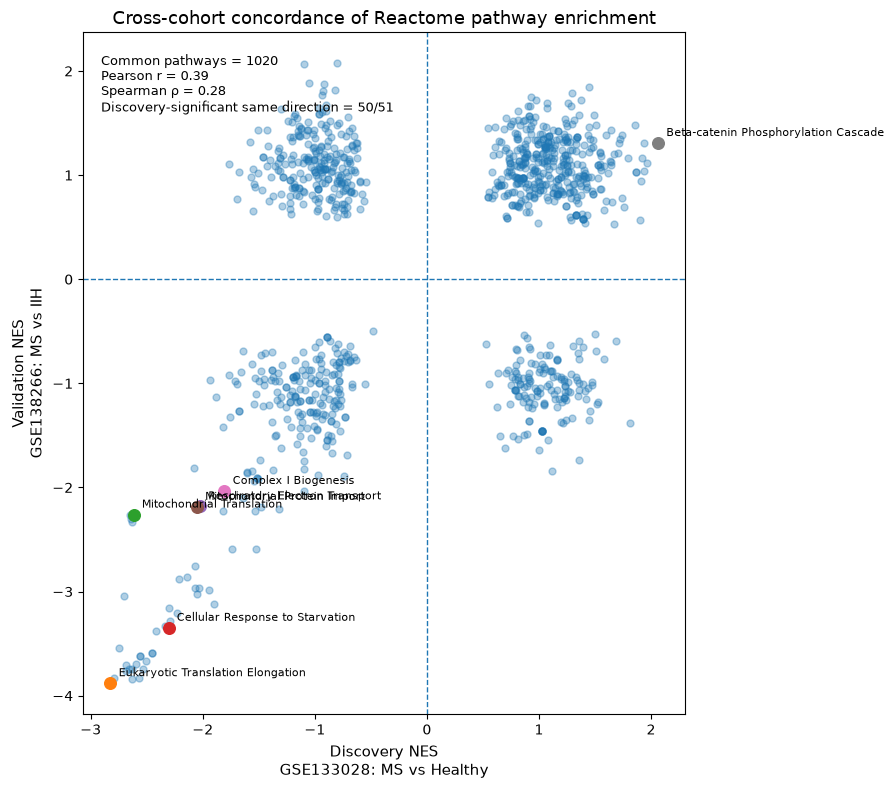

Saved:
../figures/GSE133028_vs_GSE138266_Reactome_NES_concordance.png


In [35]:
# ============================================================
# STEP 34 — CROSS-COHORT REACTOME NES CONCORDANCE FIGURE
# ============================================================
#
# PURPOSE
# ------------------------------------------------------------
#
# Visualize pathway-level agreement between:
#
#   Discovery:
#       GSE133028
#       MS vs Healthy
#
#   Validation:
#       GSE138266
#       MS vs IIH
#
#
# Each point = one Reactome pathway.
#
# X-axis:
#       discovery NES
#
# Y-axis:
#       validation NES
#
#
# Quadrants:
#
#   lower-left  -> negative in both cohorts
#   upper-right -> positive in both cohorts
#
# The dominant replicated program should therefore appear
# mainly in the lower-left quadrant.
#
#
# IMPORTANT:
#
# We highlight only a few representative pathways.
# Reactome contains many overlapping/redundant translation
# and mitochondrial gene sets, so labeling every significant
# pathway would exaggerate their independence.
#
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os


os.makedirs("../figures", exist_ok=True)


# ------------------------------------------------------------
# Representative pathways
# ------------------------------------------------------------

representative_terms = [
    "Eukaryotic Translation Elongation",
    "Mitochondrial Translation",
    "Cellular Response to Starvation",
    "Respiratory Electron Transport",
    "Mitochondrial Protein Import",
    "Complex I Biogenesis",
    "Beta-catenin Phosphorylation Cascade"
]


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 8)
)


# All common Reactome pathways
ax.scatter(
    pathway_comparison["discovery_NES"],
    pathway_comparison["validation_NES"],
    alpha=0.35,
    s=25
)


# Zero reference lines
ax.axhline(
    0,
    linewidth=1,
    linestyle="--"
)

ax.axvline(
    0,
    linewidth=1,
    linestyle="--"
)


# ------------------------------------------------------------
# Highlight representative pathways
# ------------------------------------------------------------

for term in representative_terms:

    row = pathway_comparison[
        pathway_comparison["Term"] == term
    ]

    if len(row) == 1:

        x = row["discovery_NES"].iloc[0]
        y = row["validation_NES"].iloc[0]

        ax.scatter(
            x,
            y,
            s=70
        )

        ax.annotate(
            term,
            (x, y),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=8
        )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Discovery NES\nGSE133028: MS vs Healthy",
    fontsize=11
)

ax.set_ylabel(
    "Validation NES\nGSE138266: MS vs IIH",
    fontsize=11
)

ax.set_title(
    "Cross-cohort concordance of Reactome pathway enrichment",
    fontsize=13
)


# ------------------------------------------------------------
# Correlation information
# ------------------------------------------------------------

annotation_text = (
    f"Common pathways = {len(pathway_comparison)}\n"
    f"Pearson r = {pearson_r:.2f}\n"
    f"Spearman ρ = {spearman_rho:.2f}\n"
    f"Discovery-significant same direction = "
    f"{n_same_direction}/{n_discovery_sig}"
)


ax.text(
    0.03,
    0.97,
    annotation_text,
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=9
)


plt.tight_layout()


# ------------------------------------------------------------
# Save high-resolution figure
# ------------------------------------------------------------

figure_path = (
    "../figures/"
    "GSE133028_vs_GSE138266_Reactome_NES_concordance.png"
)


plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print("Saved:")
print(figure_path)

In [36]:
# ============================================================
# STEP 35 — RESOLVE THE 54 vs 51 PATHWAY COUNT
# ============================================================
#
# Earlier in the discovery analysis we recorded:
#
#       54 pathways with FDR < 0.05
#       50 negative
#        4 positive
#
# In the cross-cohort comparison we found:
#
#       51 discovery-significant pathways represented
#       among pathways shared with validation.
#
# We now determine WHY.
#
# Possibilities:
#
# A) The saved discovery result itself currently contains
#    only 51 significant pathways.
#
# B) It contains 54, but 3 pathways were not tested in the
#    validation cohort because the available/ranked genes
#    caused them to fail the GSEA size criteria.
#
# No analysis is rerun here.
# ============================================================


# ------------------------------------------------------------
# 1. Count significant pathways directly in saved discovery
# ------------------------------------------------------------

discovery_sig_full = discovery_gsea[
    discovery_gsea["FDR q-val"] < 0.05
].copy()


print("========================================")
print("DISCOVERY FILE")
print("========================================")

print(
    "\nTotal pathways tested:",
    len(discovery_gsea)
)

print(
    "FDR < 0.05:",
    len(discovery_sig_full)
)

print(
    "Negative FDR < 0.05:",
    int(
        (
            discovery_sig_full["NES"] < 0
        ).sum()
    )
)

print(
    "Positive FDR < 0.05:",
    int(
        (
            discovery_sig_full["NES"] > 0
        ).sum()
    )
)


# ------------------------------------------------------------
# 2. Which discovery pathways exist in validation?
# ------------------------------------------------------------

validation_terms = set(
    validation_gsea["Term"]
)


discovery_sig_full[
    "present_in_validation"
] = (
    discovery_sig_full["Term"]
    .isin(validation_terms)
)


print("\n========================================")
print("CROSS-COHORT AVAILABILITY")
print("========================================")


print(
    "\nDiscovery-significant pathways present "
    "in validation:",
    int(
        discovery_sig_full[
            "present_in_validation"
        ].sum()
    )
)


print(
    "Discovery-significant pathways absent "
    "from validation:",
    int(
        (
            ~discovery_sig_full[
                "present_in_validation"
            ]
        ).sum()
    )
)


# ------------------------------------------------------------
# 3. Print any missing pathways explicitly
# ------------------------------------------------------------

missing_from_validation = (
    discovery_sig_full[
        ~discovery_sig_full[
            "present_in_validation"
        ]
    ][
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
)


print("\n========================================")
print("SIGNIFICANT DISCOVERY PATHWAYS")
print("NOT TESTED IN VALIDATION")
print("========================================")


if len(missing_from_validation) == 0:

    print(
        "\nNone."
    )

else:

    display(
        missing_from_validation
        .sort_values("NES")
        .round(5)
    )


# ------------------------------------------------------------
# 4. Also inspect ALL Reactome terms absent in validation
# ------------------------------------------------------------

all_missing_terms = (
    discovery_gsea[
        ~discovery_gsea["Term"]
        .isin(validation_terms)
    ][
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
)


print(
    "\nAll discovery-tested pathways absent "
    "from validation:",
    len(all_missing_terms)
)

DISCOVERY FILE

Total pathways tested: 1041
FDR < 0.05: 54
Negative FDR < 0.05: 50
Positive FDR < 0.05: 4

CROSS-COHORT AVAILABILITY

Discovery-significant pathways present in validation: 51
Discovery-significant pathways absent from validation: 3

SIGNIFICANT DISCOVERY PATHWAYS
NOT TESTED IN VALIDATION


,Term,NES,FDR q-val
21,Cristae Formation,-2.30938,0.00000
24,Formation of ATP by Chemiosmotic Coupling,-2.28581,0.00004
40,Other Interleukin Signaling,-1.93023,0.00773



All discovery-tested pathways absent from validation: 21


In [37]:
# ============================================================
# STEP 36 — VALIDATION PATHWAY SENSITIVITY WITHOUT PST95809
# ============================================================
#
# PURPOSE
# ------------------------------------------------------------
#
# The PRIMARY validation analysis contained:
#
#       12 donors
#       6 MS + 6 IIH
#
# PST95809 was an unusual donor in pseudobulk PCA and had
# the smallest selected T-cell count / library.
#
# We therefore already performed a PRE-SPECIFIED sensitivity
# DE analysis excluding this donor:
#
#       11 donors
#       6 MS + 5 IIH
#
# Gene-level robustness was strong:
#
#       all-gene log2FC correlation = 0.9283
#       105 / 105 primary significant genes same direction
#
#
# Now we ask the more important question:
#
#       Does removing PST95809 materially change the
#       Reactome pathway enrichment landscape?
#
#
# We use EXACTLY the same GSEA settings:
#
#       Reactome_Pathways_2024
#       min_size = 15
#       max_size = 500
#       permutation_num = 1000
#       seed = 42
#
# ============================================================

import gseapy as gp
import pandas as pd
import numpy as np


# ============================================================
# 1. BUILD SENSITIVITY WALD-STATISTIC RANKING
# ============================================================

ranked_val_no_PST = (
    de_results_no_PST95809[
        ["stat"]
    ]
    .copy()
)


# Keep genes with finite Wald statistics
ranked_val_no_PST = ranked_val_no_PST[
    np.isfinite(
        ranked_val_no_PST["stat"]
    )
].copy()


# Add gene names explicitly
ranked_val_no_PST["gene"] = (
    ranked_val_no_PST.index.astype(str)
)


# GSEApy input format
ranked_val_no_PST = ranked_val_no_PST[
    [
        "gene",
        "stat"
    ]
]


# Rank from strongest MS-positive to strongest MS-negative
ranked_val_no_PST = (
    ranked_val_no_PST
    .sort_values(
        "stat",
        ascending=False
    )
)


print("========================================")
print("SENSITIVITY GSEA INPUT")
print("========================================")

print(
    "\nGenes with finite Wald statistic:",
    len(ranked_val_no_PST)
)

print(
    "Duplicate genes:",
    ranked_val_no_PST["gene"].duplicated().sum()
)


# ============================================================
# 2. RUN THE SAME REACTOME PRERANKED GSEA
# ============================================================

pre_res_val_no_PST = gp.prerank(
    rnk=ranked_val_no_PST,
    gene_sets="Reactome_Pathways_2024",
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    verbose=True,
    outdir=None
)


gsea_val_no_PST = (
    pre_res_val_no_PST.res2d
    .copy()
)


# Convert relevant columns to numeric
for column in [
    "ES",
    "NES",
    "NOM p-val",
    "FDR q-val",
    "FWER p-val"
]:

    gsea_val_no_PST[column] = pd.to_numeric(
        gsea_val_no_PST[column],
        errors="coerce"
    )


print("\n========================================")
print("SENSITIVITY GSEA COMPLETE")
print("========================================")

print(
    "\nPathways tested:",
    len(gsea_val_no_PST)
)

print(
    "FDR < 0.05:",
    int(
        (
            gsea_val_no_PST["FDR q-val"] < 0.05
        ).sum()
    )
)


# ============================================================
# 3. COMPARE PRIMARY vs SENSITIVITY VALIDATION GSEA
# ============================================================

validation_pathway_robustness = (
    validation_gsea[
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
    .rename(
        columns={
            "NES": "primary_NES",
            "FDR q-val": "primary_FDR"
        }
    )
    .merge(
        gsea_val_no_PST[
            [
                "Term",
                "NES",
                "FDR q-val"
            ]
        ]
        .rename(
            columns={
                "NES": "no_PST95809_NES",
                "FDR q-val": "no_PST95809_FDR"
            }
        ),
        on="Term",
        how="inner"
    )
)


# Keep finite NES values
validation_pathway_robustness = (
    validation_pathway_robustness[
        np.isfinite(
            validation_pathway_robustness["primary_NES"]
        )
        &
        np.isfinite(
            validation_pathway_robustness["no_PST95809_NES"]
        )
    ]
    .copy()
)


# ============================================================
# 4. GLOBAL NES CORRELATION
# ============================================================

from scipy.stats import pearsonr, spearmanr


val_pearson_r, _ = pearsonr(
    validation_pathway_robustness["primary_NES"],
    validation_pathway_robustness["no_PST95809_NES"]
)


val_spearman_rho, _ = spearmanr(
    validation_pathway_robustness["primary_NES"],
    validation_pathway_robustness["no_PST95809_NES"]
)


# ============================================================
# 5. STABILITY OF PRIMARY VALIDATION-SIGNIFICANT PATHWAYS
# ============================================================

primary_val_sig = (
    validation_pathway_robustness[
        validation_pathway_robustness["primary_FDR"] < 0.05
    ]
    .copy()
)


primary_val_sig["same_direction"] = (
    np.sign(
        primary_val_sig["primary_NES"]
    )
    ==
    np.sign(
        primary_val_sig["no_PST95809_NES"]
    )
)


primary_val_sig["still_FDR05"] = (
    primary_val_sig["no_PST95809_FDR"] < 0.05
)


# ============================================================
# 6. PRINT COMPACT ROBUSTNESS SUMMARY
# ============================================================

print("\n========================================")
print("VALIDATION PATHWAY ROBUSTNESS")
print("========================================")

print(
    "\nCommon pathways:",
    len(validation_pathway_robustness)
)

print(
    f"Primary vs sensitivity Pearson NES r: "
    f"{val_pearson_r:.4f}"
)

print(
    f"Primary vs sensitivity Spearman rho: "
    f"{val_spearman_rho:.4f}"
)


print(
    "\nPrimary validation FDR < 0.05 pathways:",
    len(primary_val_sig)
)


print(
    "Same direction after excluding PST95809:",
    f"{int(primary_val_sig['same_direction'].sum())}"
    f" / {len(primary_val_sig)}"
)


print(
    "Still FDR < 0.05 after excluding PST95809:",
    f"{int(primary_val_sig['still_FDR05'].sum())}"
    f" / {len(primary_val_sig)}"
)


# ============================================================
# 7. CHECK WHETHER ANY SIGNIFICANT PATHWAY REVERSES DIRECTION
# ============================================================

reversed_pathways = (
    primary_val_sig[
        ~primary_val_sig["same_direction"]
    ]
)


print(
    "\nPrimary significant pathways reversing direction:"
)


if len(reversed_pathways) == 0:

    print("None")

else:

    display(
        reversed_pathways[
            [
                "Term",
                "primary_NES",
                "primary_FDR",
                "no_PST95809_NES",
                "no_PST95809_FDR"
            ]
        ]
    )


# ============================================================
# 8. SAVE COMPLETE SENSITIVITY RESULTS
# ============================================================

gsea_val_no_PST.to_csv(
    "../results/"
    "GSE138266_Tcell_CSF_MS_vs_IIH_Reactome_GSEA_no_PST95809.csv",
    index=False
)


validation_pathway_robustness.to_csv(
    "../results/"
    "GSE138266_Tcell_CSF_MS_vs_IIH_Reactome_GSEA_robustness.csv",
    index=False
)


print("\nSensitivity results saved.")

2026-09-17 14:03:23,390 [INFO] Parsing data files for GSEA.............................
2026-09-17 14:03:23,403 [INFO] Enrichr library gene sets already downloaded in: /home/operation/.cache/gseapy, use local file
2026-09-17 14:03:23,452 [INFO] 1075 gene_sets have been filtered out when max_size=500 and min_size=15
2026-09-17 14:03:23,453 [INFO] 1030 gene_sets used for further statistical testing.....
2026-09-17 14:03:23,453 [INFO] Start to run GSEA...Might take a while..................


SENSITIVITY GSEA INPUT

Genes with finite Wald statistic: 11358
Duplicate genes: 0


2026-09-17 14:03:40,978 [INFO] Congratulations. GSEApy runs successfully................




SENSITIVITY GSEA COMPLETE

Pathways tested: 1030
FDR < 0.05: 97

VALIDATION PATHWAY ROBUSTNESS

Common pathways: 1030
Primary vs sensitivity Pearson NES r: 0.8656
Primary vs sensitivity Spearman rho: 0.8173

Primary validation FDR < 0.05 pathways: 66
Same direction after excluding PST95809: 66 / 66
Still FDR < 0.05 after excluding PST95809: 62 / 66

Primary significant pathways reversing direction:
None

Sensitivity results saved.
